# T-RAG · Notebook 5 — Full system and evaluation v2 (GPU)

## About this notebook

**What it does :** This is the **main notebook**. It runs the complete T-RAG system on all sources (news, tweets, press releases, Fed statements, prices and the knowledge graph from Notebook 4) and produces the project's final results.

It first generates the final test set, **TempFinQA-v2**. It has 317 questions built from the data, so every correct answer is known (the team read all 317 generated questions to check that each one is clear). They fall into ten categories: point-in-time, latest, trend, comparison, event impact, policy, prices, reported figures, multi-hop and unanswerable. The set includes 19 "time-trap" pairs: the same question asked on two dates, where the right answer changes.

Eight versions answer every question with the same LLM (Qwen2.5-7B-Instruct) and the same answer format. Each version adds one piece:
* B0 : the LLM alone
* B2 : standard hybrid RAG, with no notion of time
* B3 : + router and hard time filter
* B4 : + recency weighting
* B5r : + a time strategy chosen per question type
* B5 : + timeline, events and coverage tools
* B6p : + price tool and step-by-step reasoning
* B6 : + knowledge-graph tool

Answers are marked automatically: the exact option, a number within ±1.5%, or a date within ±3 days. The notebook also reports:
* 95% confidence intervals and McNemar tests;
* the router's accuracy;
* a sensitivity study of the recency settings;
* an NLI check of the explanations;
* full written reports for headline questions such as "How has Tesla's sentiment changed over the last 2 years?".

**Main result :** B6 answers 87.1% of questions correctly, against 47.0% for standard RAG and 18.3% for the LLM alone. 14.7% of standard RAG's evidence came from after the as-of date; for every time-aware version it was 0%.

**Needs :** Notebook 4's output, plus Notebook 4J's for the second answer key. GPU T4 ×2, internet on, about 4–5 hours. The `PROFILE` setting can also run a larger model; our results come from the `qwen7b` run.

**Produces :** `trag_eval_v2_qwen7b/` with the questions, the raw and scored answers of every version, `summary.json` and figures.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path

PROFILE = "qwen7b"        # "qwen7b" (your run) | "qwen14b" (teammate) | "llama8b" (optional)

ALL_VERSIONS = ["B0", "B2", "B3", "B4", "B5r", "B5", "B6p", "B6"]
PROFILES = {
    "qwen7b":  dict(LLM_MODEL="Qwen/Qwen2.5-7B-Instruct", LOAD_4BIT=False, LLM_BATCH=12,
                    VERSIONS=ALL_VERSIONS, SENSITIVITY=True, SHOWCASE=True),
    "qwen14b": dict(LLM_MODEL="Qwen/Qwen2.5-14B-Instruct", LOAD_4BIT=True, LLM_BATCH=6,
                    VERSIONS=["B0", "B2", "B4", "B5", "B6"], SENSITIVITY=False, SHOWCASE=True),
    "llama8b": dict(LLM_MODEL="kaggle:llama-3.1/transformers/8b-instruct", LOAD_4BIT=False, LLM_BATCH=12,
                    VERSIONS=["B0", "B2", "B4", "B5", "B6"], SENSITIVITY=False, SHOWCASE=False),
}
globals().update(PROFILES[PROFILE]); RUN_NAME = PROFILE
GEN_PRIORITY = ["B0", "B2", "B5", "B6", "B4", "B6p", "B3", "B5r"]   # order of generation if time runs short

RERANK_MODEL = "BAAI/bge-reranker-base"
NLI_MODEL = "cross-encoder/nli-deberta-v3-base"
END = "2023-12-31"                         # default as-of date
TOP_K, N_EACH, N_RERANK = 8, 100, 50
HALF_LIFE_DAYS, LAMBDA, HALF_LIFE_EVENT, LATEST_DAYS = 30, 0.5, 5, 120
MIN_N = {"news": 20, "social": 10}          # documents for a month to count
QUARTER_MIN_N = {"news": 60, "social": 30}
POS_T, NEG_T, MIX_T = 0.25, -0.25, 0.08
MAX_NEW_TOKENS, MAX_NEW_TOKENS_STEPS = 160, 320
MAX_HOURS = 10.5                            # Kaggle stops sessions at 12 h
PILOT = False                               # True → 2 questions per template (≈ 20 min check)
SEED = 42

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path(f"/kaggle/working/trag_eval_v2_{RUN_NAME}") if ON_KAGGLE else Path(f"trag_eval_v2_{RUN_NAME}")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
print("Run:", RUN_NAME, "|", LLM_MODEL, "| versions", VERSIONS, "| output", OUT.resolve())

Run: qwen7b | Qwen/Qwen2.5-7B-Instruct | versions ['B0', 'B2', 'B3', 'B4', 'B5r', 'B5', 'B6p', 'B6'] | output /kaggle/working/trag_eval_v2_qwen7b


In [2]:
!pip install -q sentence-transformers accelerate bitsandbytes

In [3]:
import re, json, time, glob, pickle, warnings, traceback
from collections import defaultdict
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import binomtest
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 120)
N_GPU = torch.cuda.device_count()
DEV0 = "cuda:0" if N_GPU else "cpu"
print("torch", torch.__version__, "| GPUs:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
SUMMARY, T0 = {"run": RUN_NAME, "llm": LLM_MODEL, "versions": VERSIONS}, time.time()
def hours(): return (time.time() - T0) / 3600

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel", "ALL": "the market"}

torch 2.11.0+cu130 | GPUs: 2 ['Tesla T4', 'Tesla T4']


## Step 1 — Load Notebook 4's index (and the LLM-judge labels, if attached)

In [4]:
def find_input(name, folder="trag_index_v2"):
    hits = sorted(glob.glob(f"/kaggle/input/**/{folder}/{name}", recursive=True)) + sorted(glob.glob(f"{folder}/{name}"))
    return hits[0] if hits else None
def need(name):
    p = find_input(name)
    if p is None: raise FileNotFoundError(f"trag_index_v2/{name} not found — attach Notebook 4's output.")
    return p

chunks = pd.read_parquet(need("chunks_v2.parquet"))
E = np.load(need("embeddings_v2.npy")).astype(np.float32)
assert len(chunks) == len(E), "chunks and embeddings are out of sync"
events = pd.read_parquet(need("events_v2.parquet"))
prices = pd.read_parquet(need("prices.parquet"))
TRADING_DAYS = pd.DatetimeIndex(pd.read_parquet(need("trading_days.parquet"))["date"])
coverage = pd.read_csv(need("coverage_v2.csv"))
manifest = json.loads(Path(need("manifest_v2.json")).read_text())
release_facts = pd.read_parquet(find_input("release_facts.parquet")) if find_input("release_facts.parquet") else pd.DataFrame()
releases = pd.read_parquet(find_input("releases.parquet")) if find_input("releases.parquet") else pd.DataFrame()
G = pickle.load(open(need("graph/graph.pkl"), "rb"))
jp = sorted(glob.glob("/kaggle/input/**/trag_judge/llm_labels.parquet", recursive=True)) + sorted(glob.glob("trag_judge/llm_labels.parquet"))
judge = pd.read_parquet(jp[0]) if jp else None
EMBED_MODEL, QUERY_PREFIX = manifest["embedder"], manifest["query_prefix"]
events["day0"] = pd.to_datetime(events.day0); events["event_date"] = pd.to_datetime(events.event_date)
print(f"{len(chunks):,} documents", chunks.source.value_counts().to_dict())
print(f"events {len(events):,} | revenue quarters {len(release_facts)} | graph {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges"
      f" | judge labels: {'yes' if judge is not None else 'no'}")

chunks["day0"] = pd.to_datetime(chunks.day0)
TICK = chunks.ticker.astype(str).values
SRC = chunks.source.astype(str).values
AV = pd.to_datetime(chunks.available_at, utc=True).values.astype("datetime64[ns]").astype(np.int64)   # UTC ns
DAY0 = chunks.day0.values.astype("datetime64[ns]")
POS = (chunks.label == "positive").values
NEG = (chunks.label == "negative").values
DOC_ID = chunks.doc_id.astype(str).values
DOC_IX = {d: i for i, d in enumerate(DOC_ID)}
PER_M = chunks.day0.dt.to_period("M")
PER_Q = chunks.day0.dt.to_period("Q")
DAY_NS = 86_400 * 10**9
coverage["coverage_start"] = pd.to_datetime(coverage.coverage_start)
coverage["coverage_end"] = pd.to_datetime(coverage.coverage_end)
COV = {(r.ticker, r.source): (r.coverage_start, r.coverage_end) for r in coverage.itertuples()}

J_HAS = J_POS = J_NEG = None
if judge is not None:
    jl = pd.DataFrame({"doc_id": DOC_ID}).merge(judge[["doc_id", "judge_label"]].drop_duplicates("doc_id"), on="doc_id", how="left")
    J_HAS = jl.judge_label.notna().values
    J_POS = (jl.judge_label == "positive").values
    J_NEG = (jl.judge_label == "negative").values
    print(f"LLM-judge labels available for {J_HAS.mean():.1%} of documents "
          f"(news {J_HAS[SRC == 'news'].mean():.1%}, social {J_HAS[SRC == 'social'].mean() if (SRC == 'social').any() else 0:.1%})")

prices["date"] = pd.to_datetime(prices.date)
RET = prices.pivot_table(index="date", columns="ticker", values="ret").sort_index()
ARW = prices.pivot_table(index="date", columns="ticker", values="ar").sort_index()
ZW = prices.pivot_table(index="date", columns="ticker", values="z").sort_index()

def ts(x): return pd.Timestamp(str(x)) if isinstance(x, np.str_) else pd.Timestamp(x)
def day_start(d): return ts(d).tz_localize("America/New_York").value
def cutoff(d): return (ts(d).tz_localize("America/New_York") + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)).value

def time_mask(t, start=None, end=None, as_of=None, srcs=("news",)):
    m = (TICK == t) & np.isin(SRC, list(srcs))
    if start is not None: m &= AV >= day_start(start)
    if end is not None:   m &= AV <= cutoff(end)
    if as_of is not None: m &= AV <= cutoff(as_of)
    return m

def lab_arrays(lab):
    if lab == "finbert": return POS, NEG, None
    if J_HAS is None: raise ValueError("no judge labels loaded")
    return J_POS, J_NEG, J_HAS

def tone_of(m, lab="finbert"):
    P, N, H = lab_arrays(lab)
    if H is not None: m = m & H
    pos, neg = int(P[m].sum()), int(N[m].sum())
    return (pos - neg) / (pos + neg + 1), int(m.sum())

def tone_label(x):
    if x >= POS_T: return "positive"
    if x <= NEG_T: return "negative"
    if abs(x) <= MIX_T: return "mixed"
    return None

_tables = {}
def period_table(t, src, freq="M", lab="finbert"):
    key = (t, src, freq, lab)
    if key not in _tables:
        P, N, H = lab_arrays(lab)
        m = (TICK == t) & (SRC == src)
        if H is not None: m &= H
        per = (PER_M if freq == "M" else PER_Q)[m].values
        g = pd.DataFrame({"per": per, "pos": P[m], "neg": N[m]}).groupby("per").agg(
            n=("pos", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index()
        g["tone"] = (g.pos - g.neg) / (g.pos + g.neg + 1)
        g["start"] = g.per.dt.start_time; g["end"] = g.per.dt.end_time.dt.normalize()
        cs, ce = COV.get((t, src), (pd.Timestamp("2100-01-01"), pd.Timestamp("1900-01-01")))
        need = (MIN_N if freq == "M" else QUARTER_MIN_N)[src]
        g["ok"] = (g.n >= need) & (g.start >= cs) & (g.start <= ce) & (g.end <= ts(END))
        _tables[key] = g.sort_values("per").reset_index(drop=True)
    return _tables[key]

def excess_return(t, s, e, as_of=None):
    e2 = min(ts(e), ts(as_of)) if as_of is not None else ts(e)
    r = RET.loc[(RET.index >= ts(s)) & (RET.index <= e2)]
    if len(r) < 2 or t not in r or "QQQ" not in r: return None
    st = float((1 + r[t].fillna(0)).prod() - 1); mk = float((1 + r["QQQ"].fillna(0)).prod() - 1)
    return st, mk, st - mk, len(r)

def truth_from_spec(spec, lab="finbert"):
    """The answer key of a question, recomputed from a given set of labels. None = no clear answer."""
    if isinstance(spec, str): spec = json.loads(spec)
    k = spec["kind"]
    if k == "fixed": return spec["truth"]
    t, src = spec["t"], spec.get("src", "news")
    if k == "month_label":
        g = period_table(t, src, "M", lab); r = g[(g.per.astype(str) == spec["per"]) & g.ok]
        return tone_label(r.tone.iloc[0]) if len(r) else None
    if k == "window_label":
        x, n = tone_of(time_mask(t, spec["start"], spec["end"], srcs=[src]), lab)
        return tone_label(x) if n >= spec["min_n"] else None
    if k == "trend":
        g = period_table(t, src, "M", lab)
        ok = g[g.ok & (g.start >= ts(spec["start"])) & (g.end <= ts(spec["end"]))]
        if len(ok) < 4: return None
        d = ok.tone.iloc[-2:].mean() - ok.tone.iloc[:2].mean()
        return None if abs(d) < 0.3 else ("improved" if d > 0 else "worsened")
    if k == "extreme":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone", ascending=(spec["which"] == "most negative"))
        return None if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05 else srt.per.iloc[0].strftime("%Y-%m")
    if k == "quarter_compare":
        g = period_table(t, src, "Q", lab)
        a = g[(g.per.astype(str) == spec["pa"]) & g.ok]; b = g[(g.per.astype(str) == spec["pb"]) & g.ok]
        if not len(a) or not len(b) or abs(a.tone.iloc[0] - b.tone.iloc[0]) < 0.25: return None
        return spec["la"] if a.tone.iloc[0] > b.tone.iloc[0] else spec["lb"]
    if k == "before_after":
        d = ts(spec["d"])
        xb, nb = tone_of(time_mask(t, d - pd.Timedelta(days=28), d - pd.Timedelta(days=1), srcs=[src]), lab)
        xa, na = tone_of(time_mask(t, d, d + pd.Timedelta(days=27), srcs=[src]), lab)
        if min(nb, na) < 15 or abs(xa - xb) < 0.2: return None
        return "after" if xa > xb else "before"
    if k == "m1":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone")
        if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05: return None
        r = srt.iloc[0]; x = excess_return(t, r.start, r.end)
        if x is None or abs(x[2]) < 0.03: return None
        return "outperformed" if x[2] > 0 else "underperformed"
    raise ValueError(k)

TEXT = chunks.text_for_scoring.astype(str).values
CHUNK_TEXT = chunks.chunk_text.astype(str).values
SCORE, LABEL = chunks.score.values, chunks.label.values
DAY0_STR = chunks.day0.dt.strftime("%Y-%m-%d").values
SRC_NAME = {"news": "news", "social": "tweet", "filing": "SEC filing", "fed": "Federal Reserve"}
print(coverage.to_string(index=False))

108,054 documents {'social': 57516, 'news': 49993, 'filing': 521, 'fed': 24}
events 740 | revenue quarters 88 | graph 1,598 nodes, 4,269 edges | judge labels: no
ticker source coverage_start coverage_end  n_docs  months_covered
  AAPL filing     2021-01-28   2023-11-03      48              12
  AAPL   news     2022-06-01   2023-12-31    8002              19
  AAPL social     2021-10-01   2022-09-30    4930              12
   AMD filing     2021-01-27   2023-11-01      52              13
   AMD   news     2021-01-01   2023-12-31    4465              35
   AMD social     2021-10-01   2022-09-30    2182              12
  AMZN filing     2021-02-03   2023-10-27      48              12
  AMZN   news     2023-03-01   2023-12-31    4293              10
  AMZN social     2021-10-01   2022-09-30    4005              12
 GOOGL filing     2021-02-03   2023-10-25      52              12
 GOOGL   news     2021-01-01   2023-12-31    5077              36
 GOOGL social     2021-10-01   2022-09-30    1

## Step 2 — TempFinQA-v2: questions generated from the data

Every answer is computed from the data, so it is known exactly. Each sentiment question also stores **how** its answer was computed (`spec`), so the answer can be recomputed with the LLM judge's labels instead of FinBERT's (the "dual answer key").

| Template | Category | Source | Answer from |
|---|---|---|---|
| T1 / T1s | point-in-time | news / tweets | monthly net tone |
| T2 / T4s | latest | news / tweets | last four weeks |
| T3 | latest (time-trap pairs) | press releases | earnings dates (SEC) |
| T9 | latest (time-trap pairs) | press releases | **reported revenue (SEC XBRL)** |
| T13 | reported figures | press releases | quarterly revenue (XBRL), ±1.5% |
| T4, T5 | trend | news | monthly tone |
| T6 | comparison | news | quarterly tone |
| T7 | event impact | news + filings | CAR[−1,+3] of earnings |
| T10 | prices | prices | stock vs Nasdaq-100 over a quarter |
| T11 | policy | news + filings | CAR[−1,+3] after a government action |
| T12 | policy | Fed statements | the Fed's decision (raise / hold / cut) |
| M1 | multi-hop | news + prices | the most negative month → did the stock beat the index that month? |
| M2 | multi-hop | news | tone four weeks before vs after an earnings report |
| M3 | multi-hop | prices + graph | on the company's worst day, which other company also moved sharply? |
| T8 | unanswerable | all | no coverage, future events, results not yet published |

the team read all 317 generated questions to check that each one is clear

In [5]:
rng = np.random.default_rng(SEED)
QS = []
def add(**kw):
    for k in ("periods", "event_date", "trap_group"): kw.setdefault(k, None)
    kw.setdefault("spec", {"kind": "fixed", "truth": kw["truth"]})
    kw["spec"] = json.dumps(kw["spec"], default=str)
    QS.append(kw)
END_TS = ts(END)
OPTS_TONE = ["positive", "negative", "mixed"]
D = pd.Timedelta
NEWS_T = [t for t in TICKERS if (t, "news") in COV]
SOC_T = [t for t in TICKERS if (t, "social") in COV]
EVT = events[(events.ticker_scope != "ALL") & events.ticker.isin(TICKERS)].copy()
def fmt(d): return pd.Timestamp(d).strftime("%Y-%m-%d")

# ---- T1 / T1s: month tone (news, tweets)
for src, tick, per_t in (("news", NEWS_T, 3), ("social", SOC_T, 2)):
    for t in tick:
        m = period_table(t, src, "M"); m = m[m.ok].copy(); m["lab"] = m.tone.map(tone_label)
        for lab in [str(x) for x in rng.permutation(OPTS_TONE)]:
            c = m[m.lab == lab]
            if not len(c) or sum(q["ticker"] == t and q["template"].startswith("T1") and q["source"] == src for q in QS) >= per_t: continue
            r = c.iloc[rng.integers(len(c))]
            what = (f"Was news coverage of {COMPANY[t]} in {r.per.strftime('%B %Y')}" if src == "news" else
                    f"On social media (Twitter), was the mood about {COMPANY[t]} in {r.per.strftime('%B %Y')}")
            add(template="T1 month tone" if src == "news" else "T1s social month tone", category="point-in-time", intent="point_in_time",
                ticker=t, as_of=END, source=src, question=f"{what} mostly positive, mostly negative, or mixed?",
                answer_type="choice", options=OPTS_TONE, truth=lab, spec={"kind": "month_label", "t": t, "src": src, "per": str(r.per)},
                truth_start=r.start, truth_end=r.end, router_start=r.start, router_end=r.end)

# ---- T2 / T4s: latest tone (last four weeks before the as-of date)
for src, tick, per_t in (("news", NEWS_T, 3), ("social", SOC_T, 2)):
    for t in tick:
        cs, ce = COV[(t, src)]
        cands = TRADING_DAYS[(TRADING_DAYS >= cs + D(days=60)) & (TRADING_DAYS <= min(ce, END_TS))]
        if not len(cands): continue
        got = {}
        for d in rng.choice(cands.values, size=min(150, len(cands)), replace=False):
            d = ts(d); spec = {"kind": "window_label", "t": t, "src": src, "start": fmt(d - D(days=27)), "end": fmt(d), "min_n": MIN_N[src]}
            lab = truth_from_spec(spec)
            if lab and lab not in got: got[lab] = (d, spec)
            if len(got) == per_t: break
        for lab, (d, spec) in got.items():
            a = fmt(d)
            what = (f"what is the recent mood in news about {COMPANY[t]}" if src == "news" else
                    f"what is the recent mood on social media (Twitter) about {COMPANY[t]}")
            add(template="T2 latest tone" if src == "news" else "T4s social latest tone", category="latest", intent="latest", ticker=t,
                as_of=a, source=src, question=f"As of {a}, {what}: mostly positive, mostly negative, or mixed?",
                answer_type="choice", options=OPTS_TONE, truth=lab, spec=spec, truth_start=d - D(days=27), truth_end=d,
                router_start=d - D(days=LATEST_DAYS), router_end=d)

# ---- T3: latest earnings date, time-trap pairs (all ten companies, from SEC filings)
for t in TICKERS:
    ev = sorted(EVT[(EVT.ticker == t) & (EVT.label == "earnings") & (EVT.event_date >= ts("2021-03-01"))].event_date.drop_duplicates())
    pairs = [(a, b) for a, b in zip(ev[:-1], ev[1:]) if (b - a).days >= 50 and b + D(days=20) <= END_TS]
    if not pairs: continue
    a, b = pairs[rng.integers(len(pairs))]
    for e1, as_of in ((a, a + D(days=20)), (b, b + D(days=20))):
        s = fmt(as_of)
        add(template="T3 latest earnings date", category="latest", intent="latest", ticker=t, as_of=s, source="filing",
            question=f"As of {s}, on what date did {COMPANY[t]} most recently report quarterly earnings?",
            answer_type="date", options=None, truth=fmt(e1), truth_start=e1 - D(days=2), truth_end=min(e1 + D(days=10), as_of),
            router_start=as_of - D(days=LATEST_DAYS), router_end=as_of, trap_group=f"T3_{t}")

# ---- T9: latest reported revenue, time-trap pairs;  T13: revenue for a named quarter
if len(release_facts):
    rf = release_facts.copy()
    for c in ("period_start", "period_end", "release_filed"): rf[c] = pd.to_datetime(rf[c])
    rel_f = pd.to_datetime(releases.filed) if len(releases) else pd.Series(dtype="datetime64[ns]")
    for t in TICKERS:
        g = rf[rf.ticker == t].sort_values("period_end").reset_index(drop=True)
        pairs = []
        for i in range(len(g) - 1):
            q1, q2 = g.iloc[i], g.iloc[i + 1]
            if abs((q2.period_start - q1.period_end).days - 1) > 5: continue            # consecutive quarters only
            A = q2.release_filed - D(days=5)
            between = ((releases.ticker == t) & (rel_f > q1.release_filed) & (rel_f <= A)).sum() if len(releases) else 0
            if between == 0 and A > q1.release_filed + D(days=20) and q2.release_filed + D(days=10) <= END_TS:
                pairs.append((q1, q2, A))
        if pairs:
            q1, q2, A = pairs[rng.integers(len(pairs))]
            for q, as_of in ((q1, A), (q2, q2.release_filed + D(days=10))):
                s = fmt(as_of)
                add(template="T9 latest revenue", category="latest", intent="latest", ticker=t, as_of=s, source="filing",
                    question=f"As of {s}, what was {COMPANY[t]}'s most recently reported quarterly revenue, in billions of US dollars?",
                    answer_type="number", options=None, truth=f"{q.revenue_bn:.3f}",
                    truth_start=q.release_filed - D(days=1), truth_end=q.release_filed + D(days=3),
                    router_start=as_of - D(days=LATEST_DAYS), router_end=as_of, trap_group=f"T9_{t}")
        for i in rng.permutation(len(g))[:2]:
            q = g.iloc[i]; e = q.period_end
            add(template="T13 quarter revenue", category="reported figures", intent="reported_figure", ticker=t, as_of=END, source="filing",
                question=f"What total revenue did {COMPANY[t]} report for its fiscal quarter that ended on {fmt(e)}? Answer in billions of US dollars.",
                answer_type="number", options=None, truth=f"{q.revenue_bn:.3f}", truth_start=q.release_filed - D(days=1),
                truth_end=q.release_filed + D(days=3), router_start=e, router_end=min(e + D(days=70), END_TS))

# ---- T4: trend direction;  T5: extreme month  (news)
for t in NEWS_T:
    cm = period_table(t, "news", "M"); cm = cm[cm.start >= COV[(t, "news")][0]].reset_index(drop=True)
    used, n_added = set(), 0
    for _ in range(80):
        L = int(rng.choice([6, 9, 12])); i = int(rng.integers(0, max(1, len(cm) - L + 1)))
        win = cm.iloc[i:i + L]
        if len(win) < L or win.ok.sum() < L - 1 or (i, L) in used: continue
        spec = {"kind": "trend", "t": t, "src": "news", "start": fmt(win.start.iloc[0]), "end": fmt(win.end.iloc[-1])}
        lab = truth_from_spec(spec)
        if lab is None: continue
        used.add((i, L)); n_added += 1
        s, e = win.start.iloc[0], win.end.iloc[-1]
        add(template="T4 trend direction", category="trend", intent="trend", ticker=t, as_of=END, source="news",
            question=f"Between {win.per.iloc[0].strftime('%B %Y')} and {win.per.iloc[-1].strftime('%B %Y')}, did news sentiment about {COMPANY[t]} generally improve or worsen?",
            answer_type="choice", options=["improved", "worsened"], truth=lab, spec=spec, truth_start=s, truth_end=e, router_start=s, router_end=e)
        if n_added == 2: break
    s2 = END_TS - pd.DateOffset(years=2) + D(days=1)
    spec = {"kind": "trend", "t": t, "src": "news", "start": fmt(s2), "end": END}
    lab = truth_from_spec(spec)
    if lab:
        add(template="T4 trend direction", category="trend", intent="trend", ticker=t, as_of=END, source="news",
            question=f"Over the two years up to {END}, did news sentiment about {COMPANY[t]} generally improve or worsen?",
            answer_type="choice", options=["improved", "worsened"], truth=lab, spec=spec, truth_start=s2, truth_end=END_TS,
            router_start=s2, router_end=END_TS)
    for y in (2022, 2023):
        which = "most negative" if (y + len(t)) % 2 == 0 else "most positive"
        spec = {"kind": "extreme", "t": t, "src": "news", "year": y, "which": which}
        lab = truth_from_spec(spec)
        if lab:
            add(template="T5 extreme month", category="trend", intent="trend", ticker=t, as_of=END, source="news",
                question=f"In {y}, which month had the {which} news sentiment about {COMPANY[t]}?", answer_type="month", options=None,
                truth=lab, spec=spec, truth_start=ts(f"{y}-01-01"), truth_end=ts(f"{y}-12-31"),
                router_start=ts(f"{y}-01-01"), router_end=ts(f"{y}-12-31"))

# ---- T6: comparison of two quarters (news)
for t in NEWS_T:
    q = period_table(t, "news", "Q"); q = q[q.ok].reset_index(drop=True)
    pairs = [(i, j) for i in range(len(q)) for j in range(i + 2, len(q)) if abs(q.tone[i] - q.tone[j]) >= 0.25]
    for k in rng.permutation(len(pairs))[:3]:
        i, j = pairs[k]; A, B = q.iloc[i], q.iloc[j]
        la, lb = f"Q{A.per.quarter} {A.per.year}", f"Q{B.per.quarter} {B.per.year}"
        first, second = (la, lb) if rng.random() < .5 else (lb, la)
        spec = {"kind": "quarter_compare", "t": t, "src": "news", "pa": str(A.per), "pb": str(B.per), "la": la, "lb": lb}
        add(template="T6 quarter comparison", category="comparison", intent="comparison", ticker=t, as_of=END, source="news",
            question=f"Was news sentiment about {COMPANY[t]} more positive in {first} or in {second}?", answer_type="choice",
            options=[first, second], truth=truth_from_spec(spec), spec=spec, truth_start=A.start, truth_end=B.end,
            router_start=A.start, router_end=B.end, periods=[[fmt(A.start), fmt(A.end)], [fmt(B.start), fmt(B.end)]])

# ---- T7: earnings impact (sign of CAR[-1,+3])
def car_known(day0, as_of):
    i = TRADING_DAYS.searchsorted(ts(day0)); j = TRADING_DAYS.searchsorted(ts(as_of), side="right") - 1
    return i + 3 <= j
for t in NEWS_T:
    ev = EVT[(EVT.ticker == t) & (EVT.label == "earnings") & (EVT.day0 >= COV[(t, "news")][0] + D(days=7)) & (EVT.car_m1_p3.abs() >= 0.03)].copy()
    ev["n_news"] = [time_mask(t, d - D(days=1), d + D(days=5)).sum() for d in ev.event_date]
    ev = ev[ev.n_news >= 3]
    picks = pd.concat([ev[ev.car_m1_p3 > 0].sample(min(2, (ev.car_m1_p3 > 0).sum()), random_state=SEED),
                       ev[ev.car_m1_p3 < 0].sample(min(2, (ev.car_m1_p3 < 0).sum()), random_state=SEED)]).head(3)
    for r in picks.itertuples():
        d = fmt(r.event_date)
        add(template="T7 earnings impact", category="event impact", intent="event_impact", ticker=t, as_of=END, source="news+filing",
            question=f"Relative to the overall market, did {COMPANY[t]}'s stock rise or fall in the days after the quarterly earnings it reported on {d}?",
            answer_type="choice", options=["rose", "fell"], truth="rose" if r.car_m1_p3 > 0 else "fell",
            truth_start=r.event_date - D(days=1), truth_end=r.event_date + D(days=7),
            router_start=r.event_date - D(days=3), router_end=r.event_date + D(days=10), event_date=d)

# ---- T10: stock vs Nasdaq-100 over a quarter
for t in TICKERS:
    rows = []
    for p in pd.period_range("2021Q1", "2023Q4", freq="Q"):
        x = excess_return(t, p.start_time, p.end_time.normalize())
        if x and abs(x[2]) >= 0.05: rows.append((p, x[2]))
    for want in ("outperformed", "underperformed"):
        c = [(p, e) for p, e in rows if (e > 0) == (want == "outperformed")]
        if not c: continue
        p, e = c[rng.integers(len(c))]
        add(template="T10 quarter vs index", category="prices", intent="point_in_time", ticker=t, as_of=END, source="prices",
            question=f"Did {COMPANY[t]}'s stock outperform or underperform the Nasdaq-100 in Q{p.quarter} {p.year}?",
            answer_type="choice", options=["outperformed", "underperformed"], truth=want,
            truth_start=p.start_time, truth_end=p.end_time.normalize(), router_start=p.start_time, router_end=p.end_time.normalize())

# ---- T11: reaction to a government policy action
pol = EVT[(EVT.ticker_scope == "POLICY") & (EVT.car_m1_p3.abs() >= 0.02)]
for r in pol.itertuples():
    if not car_known(r.day0, END): continue
    d = fmt(r.event_date)
    add(template="T11 policy impact", category="policy", intent="event_impact", ticker=r.ticker, as_of=END, source="news+filing",
        question=f"Relative to the overall market, did {COMPANY[r.ticker]}'s stock rise or fall in the days after {r.description} on {d}?",
        answer_type="choice", options=["rose", "fell"], truth="rose" if r.car_m1_p3 > 0 else "fell",
        truth_start=r.event_date - D(days=1), truth_end=r.day0 + D(days=7),
        router_start=r.event_date - D(days=3), router_end=r.event_date + D(days=10), event_date=d)

# ---- T12: Federal Reserve decisions (public record of FOMC rate decisions, 2021–2023)
FOMC_DECISION = {**{d: "hold" for d in ["2021-01-27", "2021-03-17", "2021-04-28", "2021-06-16", "2021-07-28", "2021-09-22",
                                        "2021-11-03", "2021-12-15", "2022-01-26", "2023-06-14", "2023-09-20", "2023-11-01", "2023-12-13"]},
                 **{d: "raise" for d in ["2022-03-16", "2022-05-04", "2022-06-15", "2022-07-27", "2022-09-21", "2022-11-02",
                                         "2022-12-14", "2023-02-01", "2023-03-22", "2023-05-03", "2023-07-26"]}}
have = [d for d in FOMC_DECISION if f"fed_{d.replace('-', '')}" in DOC_IX]
for want in ("raise", "hold"):
    c = [d for d in have if FOMC_DECISION[d] == want]
    for d in [str(x) for x in rng.permutation(c)[:6]]:
        add(template="T12 Fed decision", category="policy", intent="point_in_time", ticker="ALL", as_of=END, source="fed",
            question=f"At its policy meeting that ended on {d}, did the Federal Reserve raise, cut, or hold its target for the federal funds rate?",
            answer_type="choice", options=["raise", "cut", "hold"], truth=want, truth_start=ts(d), truth_end=ts(d) + D(days=1),
            router_start=ts(d), router_end=ts(d))

# ---- M1: most negative month → did the stock beat the index that month?   M2: tone before vs after earnings
for t in NEWS_T:
    for y in (2022, 2023):
        spec = {"kind": "m1", "t": t, "src": "news", "year": y}
        lab = truth_from_spec(spec)
        if lab:
            add(template="M1 sentiment→price", category="multi-hop", intent="trend", ticker=t, as_of=END, source="news+prices",
                question=f"In {y}, in the month when news sentiment about {COMPANY[t]} was most negative, did {COMPANY[t]}'s stock outperform or underperform the Nasdaq-100?",
                answer_type="choice", options=["outperformed", "underperformed"], truth=lab, spec=spec,
                truth_start=ts(f"{y}-01-01"), truth_end=ts(f"{y}-12-31"), router_start=ts(f"{y}-01-01"), router_end=ts(f"{y}-12-31"))
    ev = EVT[(EVT.ticker == t) & (EVT.label == "earnings") & (EVT.event_date >= COV[(t, "news")][0] + D(days=30))
             & (EVT.event_date + D(days=28) <= END_TS)].event_date.drop_duplicates()
    n_m2 = 0
    for d in rng.permutation(ev.values):
        d = ts(d); spec = {"kind": "before_after", "t": t, "src": "news", "d": fmt(d)}
        lab = truth_from_spec(spec)
        if lab is None: continue
        add(template="M2 before/after earnings", category="multi-hop", intent="comparison", ticker=t, as_of=END, source="news",
            question=f"Was news sentiment about {COMPANY[t]} more positive in the four weeks before or in the four weeks after the quarterly earnings it reported on {fmt(d)}?",
            answer_type="choice", options=["before", "after"], truth=lab, spec=spec, truth_start=d - D(days=28), truth_end=d + D(days=27),
            router_start=d - D(days=28), router_end=d + D(days=27), event_date=fmt(d),
            periods=[[fmt(d - D(days=28)), fmt(d - D(days=1))], [fmt(d), fmt(d + D(days=27))]])
        n_m2 += 1
        if n_m2 == 2: break

# ---- M3: on the company's worst day of a year, which other company also moved sharply (|z| > 2)?
NAMES = [COMPANY[t] for t in TICKERS]
for t in TICKERS:
    for y in (2022, 2023):
        a = ARW[t][(ARW.index.year == y)].dropna()
        if not len(a): continue
        d = a.idxmin()
        if not (ZW.at[d, t] <= -2): continue
        co = [u for u in TICKERS if u != t and abs(ZW.at[d, u]) >= 2]
        if len(co) > 1: continue
        truth = COMPANY[co[0]] if co else "none of them"
        add(template="M3 same-day movers", category="multi-hop", intent="trend", ticker=t, as_of=END, source="prices+graph",
            question=(f"On the trading day in {y} when {COMPANY[t]}'s stock had its largest drop relative to the market, which other company among "
                      f"{', '.join(n for n in NAMES if n != COMPANY[t])} also had an unusually large move (more than 2 standard deviations)? "
                      "Answer with one company name, or 'none of them'."),
            answer_type="choice", options=[n for n in NAMES if n != COMPANY[t]] + ["none of them"], truth=truth,
            truth_start=d, truth_end=d, router_start=ts(f"{y}-01-01"), router_end=ts(f"{y}-12-31"))

# ---- T8: unanswerable
for t in NEWS_T:                                             # (a) news before coverage starts
    cs = COV[(t, "news")][0]
    if cs < ts("2021-06-01"): continue
    p = pd.Period(f"2021-{int(rng.integers(2, 12)):02d}", "M")
    if time_mask(t, p.start_time, p.end_time.normalize()).sum() < 5 and p.end_time < cs - D(days=60):
        add(template="T8 no coverage", category="unanswerable", intent="point_in_time", ticker=t, as_of=END, source="news",
            question=f"Was news coverage of {COMPANY[t]} in {p.strftime('%B %Y')} mostly positive, mostly negative, or mixed?",
            answer_type="choice", options=OPTS_TONE, truth="insufficient data", truth_start=p.start_time, truth_end=p.end_time.normalize(),
            router_start=p.start_time, router_end=p.end_time.normalize())
for t in [t for t in TICKERS if (t, "news") not in COV][:2]:   # (b) companies with no news at all
    p = pd.Period("2023-05", "M")
    add(template="T8 no coverage", category="unanswerable", intent="point_in_time", ticker=t, as_of=END, source="news",
        question=f"Was news coverage of {COMPANY[t]} in {p.strftime('%B %Y')} mostly positive, mostly negative, or mixed?",
        answer_type="choice", options=OPTS_TONE, truth="insufficient data", truth_start=p.start_time, truth_end=p.end_time.normalize(),
        router_start=p.start_time, router_end=p.end_time.normalize())
for t in SOC_T[:5]:                                         # (c) tweets outside the tweet period
    ce = COV[(t, "social")][1]
    p = pd.Period(ce + D(days=int(rng.integers(120, 400))), "M")
    if p.end_time.normalize() > END_TS: continue
    add(template="T8 no coverage", category="unanswerable", intent="point_in_time", ticker=t, as_of=END, source="social",
        question=f"On social media (Twitter), was the mood about {COMPANY[t]} in {p.strftime('%B %Y')} mostly positive, mostly negative, or mixed?",
        answer_type="choice", options=OPTS_TONE, truth="insufficient data", truth_start=p.start_time, truth_end=p.end_time.normalize(),
        router_start=p.start_time, router_end=p.end_time.normalize())
for t in NEWS_T[:5]:                                        # (d) the event is after the as-of date
    ev = EVT[(EVT.ticker == t) & (EVT.label == "earnings") & (EVT.event_date >= ts("2022-03-01"))].event_date.drop_duplicates().tolist()
    if not ev: continue
    d = ts(ev[rng.integers(len(ev))]); a = fmt(d - D(days=int(rng.integers(10, 40))))
    add(template="T8 future event", category="unanswerable", intent="event_impact", ticker=t, as_of=a, source="news+filing",
        question=f"As of {a}, relative to the overall market, did {COMPANY[t]}'s stock rise or fall in the days after the quarterly earnings it reported on {fmt(d)}?",
        answer_type="choice", options=["rose", "fell"], truth="insufficient data", truth_start=d - D(days=1), truth_end=d + D(days=7),
        router_start=d - D(days=3), router_end=ts(a), event_date=fmt(d))
if len(release_facts):                                      # (e) results not yet published
    for r in rf.sample(min(4, len(rf)), random_state=SEED).itertuples():
        a = fmt(r.period_end + D(days=7))
        if ts(a) >= r.release_filed: continue
        add(template="T8 not yet reported", category="unanswerable", intent="reported_figure", ticker=r.ticker, as_of=a, source="filing",
            question=f"As of {a}, what total revenue did {COMPANY[r.ticker]} report for its fiscal quarter that ended on {fmt(r.period_end)}? Answer in billions of US dollars.",
            answer_type="number", options=None, truth="insufficient data", truth_start=r.release_filed - D(days=1),
            truth_end=r.release_filed + D(days=3), router_start=r.period_end, router_end=ts(a))

questions = pd.DataFrame(QS).drop_duplicates("question").reset_index(drop=True)
if PILOT:
    questions = questions.groupby("template", group_keys=False).head(2).reset_index(drop=True)
questions.insert(0, "qid", [f"v2q{i:03d}" for i in range(len(questions))])
questions["query"] = questions.question.str.replace(r"^As of \d{4}-\d{2}-\d{2}, ", "", regex=True)
questions["query"] = questions["query"].str.replace(r"^(\w)", lambda m: m.group(1).upper(), regex=True)
for c in ["truth_start", "truth_end", "router_start", "router_end"]:
    questions[c] = pd.to_datetime(questions[c])

def sources_for(question):
    """Which document sources a question is about, read from its wording (same rule for every version)."""
    ql = question.lower()
    if "social media" in ql or "twitter" in ql: return ["social"]
    if "federal reserve" in ql: return ["fed"]
    if "revenue" in ql: return ["filing", "news"]
    if re.search(r"\bstock\b|earnings|react", ql): return ["news", "filing"]
    return ["news"]
questions["sources"] = questions.question.map(sources_for)

# self-check: every stored answer key reproduces exactly from its spec
bad = [q.qid for q in questions.itertuples() if json.loads(q.spec)["kind"] != "fixed" and truth_from_spec(q.spec) != q.truth]
assert not bad, f"answer keys that don't reproduce: {bad[:5]}"
print(f"{len(questions)} questions")
print(pd.crosstab(questions.template, questions.category).to_string())
print("\nAnswer balance:\n", questions.groupby("template").truth.agg(lambda s: s.value_counts().head(4).to_dict()).to_string())
questions.to_parquet(OUT / "questions_v2.parquet", index=False)
SUMMARY["n_questions"] = len(questions)
SUMMARY["questions_by_category"] = questions.category.value_counts().to_dict()
questions.sample(min(10, len(questions)), random_state=1)[["qid", "category", "as_of", "question", "truth"]]

317 questions
category                  comparison  event impact  latest  multi-hop  point-in-time  policy  prices  reported figures  trend  unanswerable
template                                                                                                                                   
M1 sentiment→price                 0             0       0          9              0       0       0                 0      0             0
M2 before/after earnings           0             0       0         15              0       0       0                 0      0             0
M3 same-day movers                 0             0       0         16              0       0       0                 0      0             0
T1 month tone                      0             0       0          0             23       0       0                 0      0             0
T10 quarter vs index               0             0       0          0              0       0      19                 0      0             0
T11 po

,qid,category,as_of,question,truth
105,v2q105,reported figures,2023-12-31,What total revenue did Apple report for its fiscal quarter that ended on 2023-07-01? Answer in billions of US dollars.,81.797
194,v2q194,event impact,2023-12-31,"Relative to the overall market, did Microsoft's stock rise or fall in the days after the quarterly earnings it repor...",fell
93,v2q093,latest,2021-08-16,"As of 2021-08-16, on what date did Alphabet most recently report quarterly earnings?",2021-07-27
297,v2q297,unanswerable,2023-12-31,"Was news coverage of Tesla in August 2021 mostly positive, mostly negative, or mixed?",insufficient data
131,v2q131,latest,2022-10-01,"As of 2022-10-01, what was AMD's most recently reported quarterly revenue, in billions of US dollars?",6.550
258,v2q258,multi-hop,2023-12-31,Was news sentiment about Tesla more positive in the four weeks before or in the four weeks after the quarterly earni...,before
80,v2q080,latest,2022-06-14,"As of 2022-06-14, what is the recent mood on social media (Twitter) about Intel: mostly positive, mostly negative, o...",mixed
263,v2q263,multi-hop,2023-12-31,"In 2023, in the month when news sentiment about Microsoft was most negative, did Microsoft's stock outperform or und...",underperformed
168,v2q168,comparison,2023-12-31,Was news sentiment about Tesla more positive in Q3 2023 or in Q4 2022?,Q3 2023
204,v2q204,event impact,2023-12-31,"Relative to the overall market, did AMD's stock rise or fall in the days after the quarterly earnings it reported on...",rose


## Step 3 — Retrieval components

BM25 (sparse matrix) + bge dense search, fused with RRF (k = 60), re-ranked by bge-reranker-base. Recency decay: score = (1 − λ)·relevance + λ·0.5^(|t − anchor| / half-life). Time-spread: the window is cut into segments and the best document of each segment is kept. Long documents (press releases, Fed statements) are shown as a **query-focused snippet**.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sentence_transformers import SentenceTransformer, CrossEncoder

cv = CountVectorizer(lowercase=True, stop_words="english", min_df=2, dtype=np.float32)
Xc = cv.fit_transform(CHUNK_TEXT)
dl = np.asarray(Xc.sum(axis=1)).ravel(); avgdl = dl.mean(); N_DOCS = Xc.shape[0]
dfreq = np.asarray((Xc > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N_DOCS - dfreq + 0.5) / (dfreq + 0.5))
Xo = Xc.tocoo(); k1, b = 1.5, 0.75
W = sparse.csc_matrix((Xo.data * (k1 + 1) / (Xo.data + k1 * (1 - b + b * dl[Xo.row] / avgdl)) * idf[Xo.col],
                       (Xo.row, Xo.col)), shape=Xc.shape)
del Xc, Xo
def bm25(query):
    cols = cv.transform([query]).indices
    return np.asarray(W[:, cols].sum(axis=1)).ravel() if len(cols) else np.zeros(N_DOCS, np.float32)
print(f"BM25 index: {N_DOCS:,} docs × {W.shape[1]:,} terms")

emb = SentenceTransformer(EMBED_MODEL, device=DEV0)
ce = CrossEncoder(RERANK_MODEL, device=DEV0, max_length=512)
if N_GPU:
    emb = emb.half()
    try: ce.model.half()
    except Exception: pass

_qcache = {}
def query_scores(query):
    if query not in _qcache:
        qv = emb.encode([QUERY_PREFIX + query], normalize_embeddings=True)[0].astype(np.float32)
        _qcache[query] = (bm25(query), E @ qv)
    return _qcache[query]

def fused(query, mask, n_each=N_EACH):
    idx = np.flatnonzero(mask)
    if len(idx) == 0: return idx
    bm, dn = query_scores(query)
    n = min(n_each, len(idx)); rrf = {}
    for ranked in (idx[np.argsort(-bm[idx])[:n]], idx[np.argsort(-dn[idx])[:n]]):
        for r, c in enumerate(ranked):
            rrf[c] = rrf.get(c, 0.0) + 1.0 / (60 + r + 1)
    return np.array(sorted(rrf, key=rrf.get, reverse=True), dtype=np.int64)

_rcache = {}
def rerank_scores(query, idx):
    todo = [i for i in idx if (query, i) not in _rcache]
    if todo:
        sc = ce.predict([(query, CHUNK_TEXT[i]) for i in todo], batch_size=64, show_progress_bar=False)
        for i, s in zip(todo, np.asarray(sc, np.float32)): _rcache[(query, i)] = float(s)
    return np.array([_rcache[(query, i)] for i in idx], np.float32)

def top_k(query, mask, anchor_ns=None, half_life=HALF_LIFE_DAYS, lam=LAMBDA, k=TOP_K):
    cand = fused(query, mask)[:N_RERANK]
    if len(cand) == 0: return []
    rel = rerank_scores(query, cand); rel = (rel - rel.min()) / (rel.max() - rel.min() + 1e-9)
    score = rel
    if anchor_ns is not None:
        score = (1 - lam) * rel + lam * 0.5 ** (np.abs(AV[cand] - anchor_ns) / (half_life * DAY_NS))
    return [int(i) for i in cand[np.argsort(-score)[:k]]]

def spread(query, mask, segs, per_seg=1):
    pool = fused(query, mask, n_each=300); picks = []
    for s, e in segs:
        sel = pool[(AV[pool] >= s) & (AV[pool] <= e)]
        picks += [int(i) for i in sel[:per_seg]]
    return sorted(set(picks), key=lambda i: AV[i])

def segments(start, end, k):
    edges = np.linspace(day_start(start), cutoff(end), k + 1).astype(np.int64)
    return list(zip(edges[:-1], edges[1:]))

STOP = set(ENGLISH_STOP_WORDS)
SNIP = {"news": 350, "social": 280, "filing": 750, "fed": 750}
def snippet(i, query):
    txt, n = TEXT[i], SNIP.get(SRC[i], 350)
    if len(txt) <= n or SRC[i] in ("news", "social"): return txt[:n]
    terms = {w for w in re.findall(r"[a-z]+", query.lower()) if w not in STOP and len(w) > 2}
    sents = re.split(r"(?<=[.!?])\s+", txt); best, bs = 0, -1.0
    for k in range(len(sents)):
        win = " ".join(sents[k:k + 4])[:n].lower()
        sc = sum(win.count(w) for w in terms) + 0.5 * len(re.findall(r"\d[\d,.]*\s*(?:billion|million|percent|%)", win))
        if sc > bs: best, bs = k, sc
    return " ".join(sents[best:best + 4])[:n]
print("Retrieval ready.")

BM25 index: 108,054 docs × 38,170 terms


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Retrieval ready.


## Step 4 — Load the LLM

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def resolve_model(name):
    """HF id, local folder, or 'kaggle:<pattern>' for a model attached from Kaggle Models."""
    if name.startswith("kaggle:"):
        pat = name.split(":", 1)[1].strip("/")
        hits = sorted(glob.glob(f"/kaggle/input/{pat}/**/config.json", recursive=True))
        hits = [h for h in hits if Path(h).parent.joinpath("tokenizer_config.json").exists()] or hits
        if not hits:
            raise FileNotFoundError(f"No model matching /kaggle/input/{pat} — attach it via Add Input → Models.")
        return str(Path(hits[0]).parent)
    return name

class LLM:
    def __init__(self, name, load_4bit=False, max_memory=None):
        path = resolve_model(name)
        self.tok = AutoTokenizer.from_pretrained(path)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        kw = {"device_map": "auto"}
        if max_memory: kw["max_memory"] = max_memory
        if load_4bit:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=torch.float16)
        try:
            self.model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, **kw)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16, **kw)
        self.model.eval()
        gc = self.model.generation_config
        gc.temperature = gc.top_p = gc.top_k = None; gc.do_sample = False

    def prompts(self, pairs):
        return [self.tok.apply_chat_template([{"role": "system", "content": s}, {"role": "user", "content": u}],
                                             tokenize=False, add_generation_prompt=True) for s, u in pairs]

    def chat(self, pairs, max_new_tokens=160, batch_size=12, name=""):
        prompts = self.prompts(pairs)
        order = np.argsort([-len(p) for p in prompts])          # longest first: an OOM shows up immediately
        outs, i, bs, t0 = [None] * len(prompts), 0, batch_size, time.time()
        while i < len(order):
            idx = order[i:i + bs]
            try:
                enc = self.tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                               add_special_tokens=False).to(self.model.device)
                with torch.inference_mode():
                    gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                              pad_token_id=self.tok.pad_token_id)
                texts = self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
                for j, txt in zip(idx, texts): outs[j] = txt
                i += len(idx)
                if (i // max(bs, 1)) % 10 == 0 or i >= len(order):
                    print(f"  {name}: {i}/{len(order)} | {time.time()-t0:5.0f}s")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); print(f"  OOM → batch size {bs}")
        return outs

def parse_json(txt):
    txt = txt or ""
    s, e = txt.find("{"), txt.rfind("}")
    if s >= 0 and e > s:
        frag = txt[s:e + 1]
        for cand in (frag, frag.replace("'", '"'), re.sub(r",\s*([}\]])", r"\1", frag)):
            try:
                out = json.loads(cand)
                if isinstance(out, dict): return out
            except Exception:
                pass
    m = re.search(r'"answer"\s*:\s*"([^"]*)"', txt)
    return {"answer": m.group(1) if m else txt.strip()[:120],
            "doc_ids": re.findall(r"(?:news_\d{7}|tw_[0-9a-f]{12}|fil_[A-Z]+_\d+_\d|fed_\d{8})", txt), "_unparsed": True}

t_load = time.time()
if N_GPU < 2 and not LOAD_4BIT:
    print("⚠️ Only one GPU visible: loading in 4-bit to fit."); LOAD_4BIT = True
llm = LLM(LLM_MODEL, load_4bit=LOAD_4BIT, max_memory={0: "6GiB" if LOAD_4BIT else "11GiB", 1: "14GiB"} if N_GPU >= 2 else None)
print(f"Loaded {LLM_MODEL} ({'4-bit' if LOAD_4BIT else 'fp16'}) in {time.time()-t_load:.0f}s")
print("Sanity check:", llm.chat([("You are helpful.", "Reply with exactly: OK, ready.")], max_new_tokens=10, name="check"))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-7B-Instruct (fp16) in 115s
  check: 1/1 |     2s
Sanity check: ['OK, ready.']


## Step 5 — The router

The LLM turns each question into a plan: question type, time window (never after the as-of date), and where relevant the two periods or the event date. A new type, **reported_figure**, covers questions about results of a period that has ended: they are published up to ~70 days later.

In [8]:
ROUTER_SYSTEM = "You turn a question about companies and markets into a retrieval plan. Reply with one JSON object only."
ROUTER_RULES = """Question types:
- point_in_time: about one specific past period (a date, a month, a quarter, a date range).
- latest: about the most recent situation as of the as-of date (recent, current, latest, most recently).
- trend: how something changed over a longer period, or which part of a period stood out.
- comparison: compares two periods: two named periods, or the weeks before vs after an event.
- event_impact: the market reaction to a specific dated event.
- reported_figure: a figure (such as revenue) reported for a period that has ended; it is published after the period ends.
- timeless: no time element.
Window rules (dates YYYY-MM-DD, never after the as-of date):
- point_in_time / trend: the period named (a date = that day; a month = its first to last day; a quarter = its three months; a year = Jan 1 to Dec 31).
- "the two years up to D" = from D minus two years plus one day, to D.
- latest: the 120 days up to the as-of date.
- comparison of two named periods: "periods" = the two periods in the order they occur; start/end cover both.
- comparison of the four weeks before vs after an event on D: "periods" = [D minus 28 days, D minus 1 day] and [D, D plus 27 days]; also give "event_date".
- event_impact: from 3 days before to 10 days after the event date; also give "event_date".
- reported_figure for a period ending on D: from D to D plus 70 days.
- timeless: {"intent": "timeless"}."""
ROUTER_EXAMPLES = [
    ("2023-12-31", "Was news coverage of Intel in March 2022 mostly positive, mostly negative, or mixed?",
     {"intent": "point_in_time", "start": "2022-03-01", "end": "2022-03-31"}),
    ("2023-06-15", "As of 2023-06-15, what is the recent mood in news about Apple: mostly positive, mostly negative, or mixed?",
     {"intent": "latest", "start": "2023-02-15", "end": "2023-06-15"}),
    ("2023-12-31", "Between January 2022 and September 2022, did news sentiment about Nvidia generally improve or worsen?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-09-30"}),
    ("2023-12-31", "Was news sentiment about AMD more positive in Q4 2023 or in Q1 2022?",
     {"intent": "comparison", "start": "2022-01-01", "end": "2023-12-31", "periods": [["2022-01-01", "2022-03-31"], ["2023-10-01", "2023-12-31"]]}),
    ("2023-12-31", "Relative to the overall market, did Microsoft's stock rise or fall in the days after the quarterly earnings it reported on 2023-04-25?",
     {"intent": "event_impact", "start": "2023-04-22", "end": "2023-05-05", "event_date": "2023-04-25"}),
    ("2022-11-20", "As of 2022-11-20, on what date did Tesla most recently report quarterly earnings?",
     {"intent": "latest", "start": "2022-07-23", "end": "2022-11-20"}),
    ("2023-12-31", "In 2022, which month had the most negative news sentiment about Alphabet?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-12-31"}),
    ("2023-12-31", "What total revenue did Amazon report for its fiscal quarter that ended on 2022-06-30? Answer in billions of US dollars.",
     {"intent": "reported_figure", "start": "2022-06-30", "end": "2022-09-08"}),
    ("2023-12-31", "At its policy meeting that ended on 2021-09-22, did the Federal Reserve raise, cut, or hold its target for the federal funds rate?",
     {"intent": "point_in_time", "start": "2021-09-22", "end": "2021-09-22"}),
    ("2023-12-31", "Was news sentiment about Intel more positive in the four weeks before or in the four weeks after the quarterly earnings it reported on 2022-07-28?",
     {"intent": "comparison", "start": "2022-06-30", "end": "2022-08-24", "periods": [["2022-06-30", "2022-07-27"], ["2022-07-28", "2022-08-24"]], "event_date": "2022-07-28"}),
    ("2022-05-10", "As of 2022-05-10, what is the recent mood on social media (Twitter) about Netflix: mostly positive, mostly negative, or mixed?",
     {"intent": "latest", "start": "2022-01-10", "end": "2022-05-10"}),
    ("2023-12-31", "Did Tesla's stock outperform or underperform the Nasdaq-100 in Q2 2021?",
     {"intent": "point_in_time", "start": "2021-04-01", "end": "2021-06-30"}),
    ("2023-12-31", "What does Nvidia make?", {"intent": "timeless"}),
]
def router_user(as_of, question):
    ex = "\n\n".join(f"As-of: {a}\nQuestion: {q}\nJSON: {json.dumps(p)}" for a, q, p in ROUTER_EXAMPLES)
    return f"{ROUTER_RULES}\n\nExamples:\n\n{ex}\n\nNow this one:\nAs-of: {as_of}\nQuestion: {question}\nJSON:"

INTENTS = {"point_in_time", "latest", "trend", "comparison", "event_impact", "reported_figure", "timeless"}
def to_date(x, default):
    try: return pd.Timestamp(str(x)[:10])
    except Exception: return default
def make_plan(raw, as_of):
    p = parse_json(raw); a = ts(as_of)
    intent = p.get("intent") if p.get("intent") in INTENTS else "point_in_time"
    start = to_date(p.get("start"), a - D(days=365)); end = min(to_date(p.get("end"), a), a)
    if start > end: start = end - D(days=365)
    periods = None
    if intent == "comparison" and isinstance(p.get("periods"), list) and len(p["periods"]) == 2:
        try: periods = [[to_date(x[0], start), min(to_date(x[1], end), a)] for x in p["periods"]]
        except Exception: periods = None
    ev = to_date(p.get("event_date"), None) if p.get("event_date") else None
    return {"intent": intent, "start": start, "end": end, "periods": periods, "event_date": ev, "raw": raw}

t_r = time.time()
router_raw = llm.chat([(ROUTER_SYSTEM, router_user(q.as_of, q.question)) for q in questions.itertuples()],
                      max_new_tokens=160, batch_size=max(LLM_BATCH, 8), name="router")
PLANS = {q.qid: make_plan(r, q.as_of) for q, r in zip(questions.itertuples(), router_raw)}
SUMMARY["router_minutes"] = round((time.time() - t_r) / 60, 1)

def iou(a0, a1, b0, b1):
    inter = (min(a1, b1) - max(a0, b0)).days + 1; union = (max(a1, b1) - min(a0, b0)).days + 1
    return max(0, inter) / union if union > 0 else 0.0
rt = pd.DataFrame([{"qid": q.qid, "category": q.category, "gold_intent": q.intent, "pred_intent": PLANS[q.qid]["intent"],
                    "iou": iou(q.router_start, min(q.router_end, ts(q.as_of)), PLANS[q.qid]["start"], PLANS[q.qid]["end"])}
                   for q in questions.itertuples()])
rt["intent_ok"] = rt.gold_intent == rt.pred_intent
rt.to_csv(OUT / "router_eval.csv", index=False)
pd.DataFrame([{"qid": k, **{kk: (str(vv) if kk != "raw" else vv) for kk, vv in v.items()}} for k, v in PLANS.items()]).to_parquet(OUT / "plans.parquet", index=False)
print(f"Router: intent accuracy {rt.intent_ok.mean():.3f} | mean window IoU {rt.iou.mean():.3f}")
print(rt.groupby("category")[["intent_ok", "iou"]].mean().round(3).to_string())
SUMMARY["router"] = {"intent_acc": round(rt.intent_ok.mean(), 3), "mean_iou": round(rt.iou.mean(), 3),
                     "by_category": rt.groupby("category")[["intent_ok", "iou"]].mean().round(3).to_dict("index")}

  OOM → batch size 6
  router: 60/317 |   220s
  router: 120/317 |   407s
  router: 180/317 |   578s
  router: 240/317 |   726s
  router: 300/317 |   936s
  router: 317/317 |  1002s
Router: intent accuracy 0.883 | mean window IoU 0.874
                  intent_ok    iou
category                          
comparison            1.000  0.854
event impact          1.000  0.902
latest                0.772  0.792
multi-hop             0.525  0.900
point-in-time         1.000  1.000
policy                1.000  0.920
prices                1.000  1.000
reported figures      1.000  0.637
trend                 1.000  1.000
unanswerable          1.000  0.750


## Step 6 — Retrieve evidence for every question and version

The company filter and the **source filter** (read from the question's wording: news, tweets, filings or Fed statements) are the same for every version; only the time handling differs. B6 adds up to three documents that the **knowledge graph** links to the events in its graph tool (vector + graph hybrid retrieval).

In [9]:
def windows(q, plan):
    a = ts(q.as_of)
    if plan["intent"] == "latest": return [(a - D(days=27), a)]
    if plan["periods"]: return [(s, e) for s, e in plan["periods"]]
    return [(plan["start"], plan["end"])]

def retrieve(q, version, plan, hl=None, lam=None, hl_event=None):
    t, query, srcs = q.ticker, q.query, q.sources
    if version == "B2":
        return top_k(query, time_mask(t, srcs=srcs)), "most relevant first"
    m = time_mask(t, plan["start"], plan["end"], as_of=q.as_of, srcs=srcs)
    if version == "B3":
        return top_k(query, m), "most relevant first"
    if version == "B4":
        return top_k(query, m, anchor_ns=cutoff(q.as_of), half_life=hl or HALF_LIFE_DAYS, lam=lam or LAMBDA), "most relevant first (recency-weighted)"
    it = plan["intent"]                                         # B5r / B5 / B6p / B6
    if it == "latest":
        return top_k(query, m, anchor_ns=cutoff(q.as_of)), "most relevant first (recency-weighted)"
    if it == "event_impact" and plan["event_date"] is not None:
        return top_k(query, m, anchor_ns=day_start(plan["event_date"]), half_life=hl_event or HALF_LIFE_EVENT), "closest to the event first"
    if it == "comparison" and plan["periods"]:
        segs, mm = [], np.zeros_like(m)
        for s, e in plan["periods"]:
            segs += segments(s, e, TOP_K // 2); mm |= time_mask(t, s, e, as_of=q.as_of, srcs=srcs)
        return spread(query, mm, segs), "in time order, spread across both periods"
    if it == "trend":
        return spread(query, m, segments(plan["start"], plan["end"], TOP_K)), "in time order, spread across the period"
    return top_k(query, m), "most relevant first"

# ---------- knowledge-graph indexes (used by B6's graph tool and graph-expanded evidence)
AFF, SAME, INV, REP, NEXT_E, EV_TICK = defaultdict(list), defaultdict(list), defaultdict(list), defaultdict(list), {}, {}
for u, v, a in G.edges(data=True):
    rel = a.get("rel")
    if rel == "AFFECTS" and v.startswith("company:"):
        tk = v.split(":", 1)[1]
        AFF[tk].append((u, ts(a["date"]), float(a.get("ar", 0)), float(a.get("car", 0)), float(a.get("z", 0))))
        EV_TICK.setdefault(u, []).append((tk, float(a.get("ar", 0))))
    elif rel == "SAME_DAY": SAME[u].append(v)
    elif rel == "INVOLVES": INV[u].append(G.nodes[v].get("name", v.split(":", 1)[1]))
    elif rel == "REPORTS" and u.startswith("doc:"): REP[v].append(u.split(":", 1)[1])
    elif rel == "NEXT": NEXT_E[u] = v
for k in AFF: AFF[k].sort(key=lambda x: x[1])

def graph_window(q, plan):
    a = ts(q.as_of); it = plan["intent"]
    if it == "latest": return a - D(days=LATEST_DAYS), a
    if it == "event_impact" and plan["event_date"] is not None: return plan["event_date"] - D(days=3), plan["event_date"] + D(days=7)
    if plan["periods"]: return plan["periods"][0][0], plan["periods"][-1][1]
    return plan["start"], plan["end"]

def graph_events(q, plan, max_n=10):
    t = q.ticker; s, e = graph_window(q, plan); e = min(e, ts(q.as_of))
    evs = [x for x in AFF.get(t, []) if s <= x[1] <= e]
    key = [x for x in evs if G.nodes[x[0]].get("kind") != "price shock"]
    shocks = sorted([x for x in evs if G.nodes[x[0]].get("kind") == "price shock"], key=lambda x: -abs(x[2]))[:5]
    sel = sorted(key, key=lambda x: -abs(x[3]))[:max_n - len(shocks)] + shocks
    return sorted(sel, key=lambda x: x[1])

def graph_docs(q, plan, k=3):
    out = []
    for node, d0, ar, car, z in sorted(graph_events(q, plan), key=lambda x: -abs(x[2]))[:3]:
        for did in REP.get(node, []):
            i = DOC_IX.get(did)
            if i is not None and SRC[i] in q.sources and AV[i] <= cutoff(q.as_of) and i not in out: out.append(i)
    return out[:k]

t_ret = time.time()
def strategy(v): return v if v in ("B2", "B3", "B4") else "B5r"      # B5, B6p and B6 share B5r's time strategy
EVID, rows = {}, []
for q in questions.itertuples():
    plan = PLANS[q.qid]
    for v in VERSIONS:
        if v == "B0": continue
        sk = strategy(v)
        if (q.qid, sk) not in EVID: EVID[(q.qid, sk)] = retrieve(q, sk, plan)
        idx, note = EVID[(q.qid, sk)]
        if v == "B6":
            extra = [i for i in graph_docs(q, plan) if i not in idx]
            idx, note = idx + extra, note + ("; then documents linked to events in the knowledge graph" if extra else "")
        EVID[(q.qid, v)] = (idx, note)
        idx = EVID[(q.qid, v)][0]
        d0 = DAY0[idx] if idx else np.array([], "datetime64[ns]")
        inwin = ((d0 >= np.datetime64(q.truth_start)) & (d0 <= np.datetime64(q.truth_end))) if idx else np.array([])
        rows.append({"qid": q.qid, "version": v, "category": q.category, "n_evidence": len(idx),
                     "temporal_precision": inwin.mean() if len(idx) else np.nan,
                     "leakage": (AV[idx] > cutoff(q.as_of)).mean() if len(idx) else 0.0})
ret_metrics = pd.DataFrame(rows)
ret_metrics.to_csv(OUT / "retrieval_per_question.csv", index=False)
VR = [v for v in VERSIONS if v != "B0"]
ret_summary = ret_metrics.groupby("version")[["n_evidence", "temporal_precision", "leakage"]].mean().reindex(VR).round(3)
print(f"Retrieval done in {time.time()-t_ret:.0f}s\n", ret_summary.to_string())
print("\nTemporal precision by category:\n",
      ret_metrics.pivot_table(index="category", columns="version", values="temporal_precision").reindex(columns=VR).round(2).to_string())
ret_summary.to_csv(OUT / "retrieval_summary.csv")
SUMMARY["retrieval"] = ret_summary.to_dict("index")

Retrieval done in 101s
          n_evidence  temporal_precision  leakage
version                                         
B2            7.950               0.333    0.147
B3            7.151               0.714    0.000
B4            7.151               0.799    0.000
B5r           7.126               0.804    0.000
B5            7.126               0.804    0.000
B6p           7.126               0.804    0.000
B6            8.997               0.796    0.000

Temporal precision by category:
 version             B2    B3    B4   B5r    B5   B6p    B6
category                                                  
comparison        0.64  0.92  0.88  0.98  0.98  0.98  0.98
event impact      0.65  0.97  0.97  0.98  0.98  0.98  0.98
latest            0.07  0.34  0.67  0.68  0.68  0.68  0.62
multi-hop         0.44  0.55  0.55  0.49  0.49  0.49  0.55
point-in-time     0.38  1.00  1.00  1.00  1.00  1.00  0.99
policy            0.30  0.94  0.93  0.98  0.98  0.98  0.98
prices            0.11  0.99 

## Step 7 — Tools and answer prompts

All tool outputs use only information available on the as-of date. An event's abnormal return over days −1..+3 (CAR) and its LLM summary are shown only once day +3 has passed.

* **Sentiment timeline** (B5+): monthly net tone for the question's source, extremes, first-vs-last change, last four weeks, coverage note.
* **Events** (B5+): earnings (with summaries), leadership changes, delivery reports, large price moves, **policy actions**, Fed decisions.
* **Prices** (B6p, B6): stock vs Nasdaq-100 over the window, monthly excess returns, event-day abnormal returns.
* **Knowledge graph** (B6): events linked to the company, other companies that moved on the same day or were hit by the same policy, entities involved, and the documents that report each event.

In [10]:
DEFINITIONS = ("Definitions: 'positive' / 'negative' = clearly more positive than negative documents (or the reverse); 'mixed' = roughly balanced. "
               "'Recent' = about the last four weeks before the as-of date. 'Improved' / 'worsened' = the last months of the period were more "
               "positive / more negative than the first months. 'Rose' / 'fell' = the stock's move relative to the overall market in the days "
               "after the event. 'Outperformed' / 'underperformed' = the stock's return minus the Nasdaq-100's return over the period. "
               "'Before' / 'after' = the four weeks before vs the four weeks after the event. Revenue answers are in billions of US dollars (e.g. 21.45).")

def coverage_note(t, src, s, e):
    if (t, src) not in COV:
        return f"There is NO {SRC_NAME[src]} coverage of {COMPANY[t]} in this dataset."
    cs, ce = COV[(t, src)]
    note = f"{SRC_NAME[src].capitalize()} coverage of {COMPANY[t]} in this dataset runs from {cs:%B %Y} to {ce:%B %Y}."
    if ts(e) < cs - D(days=31) or ts(s) > ce + D(days=31): note += " The requested period is NOT covered."
    elif ts(s) < cs or ts(e) > ce: note += " The requested period is only partly covered."
    return note

def timeline_block(q, plan):
    t, a = q.ticker, q.as_of
    src = "social" if "social" in q.sources else "news"
    if plan["intent"] == "latest": s, e = ts(a) - D(days=180), ts(a)
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        s, e = plan["event_date"] - D(days=45), min(plan["event_date"] + D(days=45), ts(a))
    else: s, e = plan["start"], plan["end"]
    g = period_table(t, src, "M") if (t, src) in COV else pd.DataFrame(columns=["per", "n", "tone", "ok", "start", "end"])
    g = g[(g.start >= ts(s).replace(day=1)) & (g.start <= min(ts(e), ts(a)))] if len(g) else g
    g = g[g.end <= ts(a)] if len(g) else g                                  # only finished months
    L = [f"TOOL · SENTIMENT TIMELINE for {COMPANY[t]} ({t}), {SRC_NAME[src]}: monthly net tone of ALL documents (FinBERT; −1 to +1; "
         f"≥ +0.25 mostly positive, ≤ −0.25 mostly negative, between −0.08 and +0.08 mixed). {coverage_note(t, src, s, e)}"]
    if len(g):
        L.append("; ".join(f"{p.strftime('%Y-%m')}: {x:+.2f} (n={n}{'' if ok else ', not counted'})" for p, x, n, ok in zip(g.per, g.tone, g.n, g.ok)))
        ok = g[g.ok]
        if len(ok) >= 4:
            f2, l2 = ok.tone.iloc[:2].mean(), ok.tone.iloc[-2:].mean()
            L.append(f"First two months average {f2:+.2f}; last two months average {l2:+.2f}; change {l2 - f2:+.2f}.")
        if len(ok) >= 2:
            lo, hi = ok.loc[ok.tone.idxmin()], ok.loc[ok.tone.idxmax()]
            L.append(f"Most negative month: {lo.per.strftime('%Y-%m')} ({lo.tone:+.2f}); most positive month: {hi.per.strftime('%Y-%m')} ({hi.tone:+.2f}).")
    else:
        L.append("No finished months with documents in this period.")
    if plan["intent"] == "latest":
        x, n = tone_of(time_mask(t, ts(a) - D(days=27), ts(a), srcs=[src]))
        L.append(f"Last four weeks up to {a}: net tone {x:+.2f} (n={n})." if n else f"No documents in the four weeks up to {a}.")
    if plan["intent"] == "comparison" and plan["periods"]:
        for s2, e2 in plan["periods"]:
            x, n = tone_of(time_mask(t, s2, e2, as_of=a, srcs=[src]))
            L.append(f"Period {s2:%Y-%m-%d} to {e2:%Y-%m-%d}: net tone {x:+.2f} (n={n}).")
    return "\n".join(L)

def ev_text(r, as_of):
    known = car_known(r.day0, as_of)
    if r.label == "policy action": what = f"policy action: {r.description}"
    elif known and isinstance(r.summary, str) and r.summary and not r.summary.startswith("No documents"): what = f"{r.label}: {r.summary}"
    else: what = r.label
    imp = f"CAR {r.car_m1_p3:+.1%}" if known and pd.notna(r.car_m1_p3) else "impact not yet known"
    return f"- {r.event_date:%Y-%m-%d} {what} (first trading day {r.day0:%Y-%m-%d}): {imp}"

def events_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        s, e = graph_window(q, plan)
        f = events[(events.ticker_scope == "ALL")].drop_duplicates("day0")
        f = f[(f.day0 >= s - D(days=1)) & (f.day0 <= min(e, a))]
        if not len(f): return "TOOL · EVENTS: no Federal Reserve decisions in this period."
        return "\n".join(["TOOL · EVENTS: Federal Reserve (FOMC) decisions:"] +
                         [f"- {r.day0:%Y-%m-%d} FOMC decision: {r.summary if isinstance(r.summary, str) and r.day0 <= a else ''}" for r in f.itertuples()])
    ev = EVT[EVT.ticker == t]
    if plan["intent"] == "latest":
        ev = ev[(ev.event_date >= a - D(days=200)) & (ev.event_date <= a) & (ev.label != "price shock")]
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        d = plan["event_date"]; ev = ev[(ev.event_date >= d - D(days=7)) & (ev.event_date <= d + D(days=7)) & (ev.event_date <= a)]
    else:
        ev = ev[(ev.event_date >= plan["start"]) & (ev.event_date <= min(plan["end"], a))]
        ev = ev[(ev.label != "price shock") | (ev.z_day0.abs() >= 3)]
        ev = ev.reindex(ev.car_m1_p3.abs().sort_values(ascending=False).index).head(10)
    if len(ev) == 0: return f"TOOL · EVENTS for {t}: none in this period."
    return "\n".join([f"TOOL · EVENTS for {t} (SEC filings, policy actions, large price moves; impact = cumulative abnormal return vs the Nasdaq-100 over days −1..+3):"]
                     + [ev_text(r, q.as_of) for r in ev.sort_values("event_date").itertuples()])

def price_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        s, e = graph_window(q, plan); x = excess_return("QQQ", s - D(days=1), e + D(days=5), as_of=a)
        return f"TOOL · PRICES: Nasdaq-100 return around {s:%Y-%m-%d}: {x[0]:+.1%}." if x else "TOOL · PRICES: no data."
    L = [f"TOOL · PRICES for {COMPANY[t]} ({t}) vs the Nasdaq-100 (only trading days up to {a:%Y-%m-%d}):"]
    if plan["intent"] == "event_impact" and plan["event_date"] is not None:
        d = plan["event_date"]; i = TRADING_DAYS.searchsorted(d)
        days = [x for x in TRADING_DAYS[max(i - 1, 0): i + 4] if x <= a]
        if days:
            L.append("Abnormal return by day: " + "; ".join(f"{x:%Y-%m-%d} {ARW.at[x, t]:+.1%}" for x in days if x in ARW.index and pd.notna(ARW.at[x, t])))
            if len(days) == 5: L.append(f"Sum over days −1..+3 (CAR): {ARW.loc[days, t].sum():+.1%}.")
        else: L.append("No trading days after this date yet.")
        return "\n".join(L)
    wins = [(a - D(days=28), a)] if plan["intent"] == "latest" else ([tuple(p) for p in plan["periods"]] if plan["periods"] else [(plan["start"], plan["end"])])
    for s, e in wins:
        x = excess_return(t, s, e, as_of=a)
        if x: L.append(f"{ts(s):%Y-%m-%d} to {min(ts(e), a):%Y-%m-%d}: stock {x[0]:+.1%}, Nasdaq-100 {x[1]:+.1%}, difference {x[2]:+.1%} ({x[3]} trading days).")
    s, e = wins[0][0], wins[-1][1]
    months = pd.period_range(ts(s), min(ts(e), a), freq="M")
    if 2 <= len(months) <= 24:
        parts = []
        for p in months:
            x = excess_return(t, p.start_time, p.end_time.normalize(), as_of=a)
            if x and p.end_time.normalize() <= a: parts.append(f"{p.strftime('%Y-%m')} {x[2]:+.1%}")
        if parts: L.append("Monthly stock-minus-index return: " + "; ".join(parts))
    return "\n".join(L)

def graph_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        return "TOOL · KNOWLEDGE GRAPH: market-wide question; see the Federal Reserve events above."
    sel = graph_events(q, plan)
    s, e = graph_window(q, plan)
    L = [f"TOOL · KNOWLEDGE GRAPH for {COMPANY[t]} ({t}), {ts(s):%Y-%m-%d} to {min(ts(e), a):%Y-%m-%d}: events linked to the company, "
         "other companies that moved sharply on the same day (|z| > 2) or were hit by the same action, entities involved, and documents reporting the event."]
    if not sel: return L[0] + "\nNo linked events in this period."
    for node, d0, ar, car, z in sel:
        n = G.nodes[node]; known = car_known(d0, q.as_of)
        desc = n.get("summary", "") if known and str(n.get("summary", "")).strip() and not str(n.get("summary")).startswith("No documents") else ""
        cat = f", {n.get('category')}" if known and n.get("category") else ""
        imp = f"day-0 abnormal return {ar:+.1%}" + (f", CAR[−1,+3] {car:+.1%}" if known else "")
        co = [f"{COMPANY.get(tk, tk)} {ar2:+.1%}" for w in SAME.get(node, []) for tk, ar2 in EV_TICK.get(w, []) if tk != t]
        if n.get("kind") in ("policy action", "FOMC decision"):
            co += [f"{COMPANY.get(tk, tk)} {ar2:+.1%}" for tk, ar2 in EV_TICK.get(node, []) if tk != t]
        docs = [d for d in REP.get(node, []) if d in DOC_IX and AV[DOC_IX[d]] <= cutoff(q.as_of)][:3]
        line = f"- {d0:%Y-%m-%d} [{n.get('kind')}{cat}] {desc} | {imp}"
        if co: line += f" | same day: {', '.join(dict.fromkeys(co))}"
        else: line += " | no other company moved sharply that day"
        if INV.get(node) and known: line += f" | involves: {', '.join(dict.fromkeys(INV[node]))}"
        if docs: line += f" | reported in: {', '.join(docs)}"
        L.append(line)
    return "\n".join(L)

def evidence_block(idx, note, query):
    if not idx: return "EVIDENCE: no documents found for this period."
    L = [f"EVIDENCE ({len(idx)} documents, {note}):"]
    for i in idx:
        L.append(f"[{DOC_ID[i]}] {DAY0_STR[i]} | {SRC_NAME[SRC[i]]} | sentiment {SCORE[i]:+.2f} ({LABEL[i]}) | {snippet(i, query)}")
    return "\n".join(L)

def allowed(q):
    if q.answer_type == "choice": return " | ".join(list(q.options) + ["insufficient data"])
    if q.answer_type == "date": return "a date in YYYY-MM-DD format, or insufficient data"
    if q.answer_type == "number": return "a number in billions of US dollars (for example 21.45), or insufficient data"
    return "a month in YYYY-MM format, or insufficient data"

TOOLS = {}
def tools_text(q, version):
    key = (q.qid, version)
    if key not in TOOLS:
        plan, parts = PLANS[q.qid], []
        if q.ticker != "ALL": parts.append(timeline_block(q, plan))
        parts.append(events_block(q, plan))
        if version in ("B6p", "B6"): parts.append(price_block(q, plan))
        if version == "B6": parts.append(graph_block(q, plan))
        TOOLS[key] = "\n\n".join(parts)
    return TOOLS[key]

def system_for(q, version):
    if version == "B0":
        return (f"You are a financial analyst. Today is {q.as_of}. Answer from your own knowledge. "
                "If you do not know, answer \"insufficient data\". Reply with one JSON object only.")
    return (f"You are a careful financial analyst. Today is {q.as_of}; you know nothing after this date. Answer using ONLY the "
            "information given below (tool outputs and evidence). If it does not cover what is asked, answer \"insufficient data\". "
            "Reply with one JSON object only.")

def tail_for(q, version):
    if version in ("B6p", "B6"):
        fmt_ = ('{"steps": ["<2-4 short reasoning steps: which tool or document, which numbers>"], "answer": "<one allowed answer>", '
                '"doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}')
    else:
        fmt_ = '{"answer": "<one allowed answer>", "doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}'
    return f"Question: {q.question}\nAllowed answers: {allowed(q)}\n{DEFINITIONS}\nReturn JSON: {fmt_}"

def body_for(q, version, evid=None):
    if version == "B0": return ""
    idx, note = evid if evid is not None else EVID[(q.qid, version)]
    parts = [tools_text(q, version)] if version in ("B5", "B6p", "B6") else []
    parts.append(evidence_block(idx, note, q.query))
    return "\n\n".join(parts) + "\n\n"

def answer_prompt(q, version, evid=None):
    return system_for(q, version), body_for(q, version, evid) + tail_for(q, version)

for tmpl in ["T12 Fed decision", "M3 same-day movers", "T9 latest revenue"]:
    ex = questions[questions.template == tmpl]
    if len(ex):
        print(f"\n######## B6 prompt — {tmpl}\n" + "\n\n".join(answer_prompt(ex.iloc[0], "B6"))[:4000])


######## B6 prompt — T12 Fed decision
You are a careful financial analyst. Today is 2023-12-31; you know nothing after this date. Answer using ONLY the information given below (tool outputs and evidence). If it does not cover what is asked, answer "insufficient data". Reply with one JSON object only.

TOOL · EVENTS: Federal Reserve (FOMC) decisions:
- 2022-06-15 FOMC decision: Fed raised interest rates to 1.5%-1.75% due to high inflation.

TOOL · PRICES: Nasdaq-100 return around 2022-06-15: -0.3%.

TOOL · KNOWLEDGE GRAPH: market-wide question; see the Federal Reserve events above.

EVIDENCE (1 documents, most relevant first):
[fed_20220615] 2022-06-15 | Federal Reserve | sentiment -0.80 (negative) | The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. In support of these goals, the Committee decided to raise the target range for the federal funds rate to 1â1/2 to 1-3/4 percent and anticipates that ongoing increases in the targ

## Step 8 — Generate the answers

Greedy decoding. Versions are generated in priority order (B0, B2, B5, B6 first) and saved one by one. If the time limit is reached, the remaining versions are skipped.

In [11]:
GEN = {}
for f in sorted(glob.glob(str(OUT / "gen_*.parquet")) + glob.glob(f"/kaggle/input/**/trag_eval_v2_{RUN_NAME}/gen_*.parquet", recursive=True)):  # resume
    g = pd.read_parquet(f)
    if "question" in g and set(g.question) == set(questions.question) and len(g) == len(questions):
        GEN[g.version.iloc[0]] = g.set_index("question").loc[questions.question, "raw"].tolist()
t_gen = time.time(); SUMMARY["gen_minutes"] = {}
for v in [v for v in GEN_PRIORITY if v in VERSIONS]:
    if v in GEN: print(f"✔ {v}: reused"); continue
    if hours() > MAX_HOURS - 0.7:
        print(f"⏱ time limit: skipping {v}"); continue
    t0 = time.time()
    pairs = [answer_prompt(q, v) for q in questions.itertuples()]
    GEN[v] = llm.chat(pairs, max_new_tokens=MAX_NEW_TOKENS_STEPS if v in ("B6p", "B6") else MAX_NEW_TOKENS,
                      batch_size=LLM_BATCH, name=v)
    pd.DataFrame({"qid": questions.qid, "question": questions.question, "version": v, "raw": GEN[v]}).to_parquet(OUT / f"gen_{v}.parquet", index=False)
    SUMMARY["gen_minutes"][v] = round((time.time() - t0) / 60, 1)
    print(f"✔ {v}: {len(pairs)} answers in {time.time()-t0:.0f}s")
DONE_V = [v for v in VERSIONS if v in GEN]

  B0: 120/317 |   111s
  B0: 240/317 |   229s
  B0: 317/317 |   300s
✔ B0: 317 answers in 300s
  OOM → batch size 6
  B2: 60/317 |   320s
  B2: 120/317 |   513s
  B2: 180/317 |   689s
  B2: 240/317 |   852s
  B2: 300/317 |  1031s
  B2: 317/317 |  1075s
✔ B2: 317 answers in 1075s
  OOM → batch size 6
  B5: 60/317 |   361s
  B5: 120/317 |   669s
  B5: 180/317 |   913s
  B5: 240/317 |  1156s
  B5: 300/317 |  1395s
  B5: 317/317 |  1414s
✔ B5: 317 answers in 1416s
  OOM → batch size 6
  B6: 60/317 |   836s
  B6: 120/317 |  1550s
  B6: 180/317 |  2236s
  B6: 240/317 |  2847s
  B6: 300/317 |  3285s
  B6: 317/317 |  3334s
✔ B6: 317 answers in 3338s
  OOM → batch size 6
  B4: 60/317 |   262s
  B4: 120/317 |   456s
  B4: 180/317 |   650s
  B4: 240/317 |   845s
  B4: 300/317 |  1049s
  B4: 317/317 |  1063s
✔ B4: 317 answers in 1063s
  OOM → batch size 6
  B6p: 60/317 |   610s
  B6p: 120/317 |  1102s
  B6p: 180/317 |  1535s
  B6p: 240/317 |  1946s
  B6p: 300/317 |  2315s
  B6p: 317/317 |  2362s
✔

## Step 9 — Scoring

* **Accuracy** by version and category. Dates are correct within ±3 days; revenue within ±1.5%; months must match exactly; unanswerable questions need "insufficient data".
* **Coverage guard** (B5, B6p, B6; rules fixed before this run): the answer becomes "insufficient data" when (1) the event is after the as-of date, (2) no results were published in the window of a reported-figure question, or (3) a sentiment question's period is less than half covered by that source. Both raw and guarded accuracy are reported.
* **Dual answer key**: if Notebook 4J's labels are attached, every sentiment question is re-scored against the LLM judge's answer key.
* Bootstrap 95% CIs, McNemar exact tests, false abstention, citation validity, and trap-pair accuracy (both questions of a pair right).

In [12]:
INSUFF = re.compile(r"insufficient|not enough|no (?:relevant )?(?:data|information|evidence|documents|articles)|cannot be determined|unknown|n/a|not (?:yet )?(?:available|reported|published)", re.I)
SYN = {"improved": ["improv", "better", "more positive"], "worsened": ["worse", "declin", "deteriorat", "more negative"],
       "rose": ["rose", "rise", "gain", "higher", "increas", "outperform"], "fell": ["fell", "fall", "drop", "lower", "declin", "underperform"],
       "positive": ["positive", "bullish", "optimis"], "negative": ["negative", "bearish", "pessimis"], "mixed": ["mixed", "neutral", "balanced"],
       "outperformed": ["outperform", "beat the", "better than the"], "underperformed": ["underperform", "lagged", "worse than the", "trailed"],
       "raise": ["rais", "hike", "increas"], "cut": ["cut", "lower", "reduc"], "hold": ["held", "hold", "unchanged", "maintain", "kept", "pause"],
       "before": ["before"], "after": ["after"], "none of them": ["none", "no other", "no company"]}

def parse_bn(a):
    s = str(a).lower().replace(",", "").replace("$", " ")
    cands = []
    for m in re.finditer(r"(?<![a-z\d.])(\d+(?:\.\d+)?)\s*(trillion|billion|bn|b|million|mn|m|thousand|k)?(?![a-z])", s):
        x, u = float(m.group(1)), (m.group(2) or "")
        pre = s[max(0, m.start() - 2):m.start()]
        if not u and (2000 <= x <= 2030 or "q" in pre or "fy" in pre): continue        # years, quarter names
        if u.startswith("tr"): x *= 1000
        elif u in ("million", "mn", "m"): x /= 1000
        elif u in ("thousand", "k"): x /= 1e6
        elif not u and x > 1000: x /= 1000                                             # a bare large number: millions
        cands.append((0 if u else 1, len(cands), x))
    return sorted(cands)[0][2] if cands else None

def normalize(q, ans):
    a = str(ans).strip()
    if INSUFF.search(a): return "insufficient data"
    al = a.lower()
    if q.answer_type == "number":
        x = parse_bn(a); return f"{x:.3f}" if x is not None else a
    if q.answer_type in ("date", "month"):
        m = re.search(r"(20\d{2})-(\d{1,2})(?:-(\d{1,2}))?", a)
        if m and (q.answer_type == "month" or m.group(3)):
            return f"{m.group(1)}-{int(m.group(2)):02d}" + (f"-{int(m.group(3)):02d}" if q.answer_type == "date" else "")
        try: return pd.Timestamp(a).strftime("%Y-%m-%d" if q.answer_type == "date" else "%Y-%m")
        except Exception: return a
    hits = [(al.find(o.lower()), o) for o in q.options if o.lower() in al]
    if hits:
        first = min(h[0] for h in hits)
        return max([h for h in hits if h[0] == first], key=lambda h: len(h[1]))[1]
    for o in q.options:
        if any(s in al for s in SYN.get(o, [])): return o
    return a

def is_correct(q, pred, truth=None):
    truth = q.truth if truth is None else truth
    if truth == "insufficient data" or pred == "insufficient data": return pred == truth
    if q.answer_type == "date":
        try: return abs((ts(pred) - ts(truth)).days) <= 3
        except Exception: return False
    if q.answer_type == "number":
        try: return abs(float(pred) - float(truth)) / float(truth) <= 0.015
        except Exception: return False
    return pred == truth

ASKS_SENT = re.compile(r"sentiment|mood|coverage of", re.I)
def guard(q, plan):
    a = ts(q.as_of)
    if plan["event_date"] is not None and plan["intent"] in ("event_impact",) and plan["event_date"] > a:
        return "event after the as-of date"
    if plan["intent"] == "reported_figure" and time_mask(q.ticker, plan["start"], plan["end"], as_of=a, srcs=["filing"]).sum() == 0:
        return "no results published by the as-of date"
    if ASKS_SENT.search(q.question):
        src = "social" if "social" in q.sources else "news"
        if (q.ticker, src) not in COV: return f"no {src} coverage"
        cs, ce = COV[(q.ticker, src)]
        for s, e in windows(q, plan):
            s, e = ts(s), min(ts(e), a); L = (e - s).days + 1
            cov = (min(e, ce) - max(s, cs)).days + 1
            if L <= 0 or cov / L < 0.5: return "period not covered"
    return None
GUARD = {q.qid: guard(q, PLANS[q.qid]) for q in questions.itertuples()}
GUARDED_V = {"B5", "B6p", "B6"}

JUDGE_TRUTH = {}
if J_HAS is not None:
    for q in questions.itertuples():
        if json.loads(q.spec)["kind"] != "fixed":
            JUDGE_TRUTH[q.qid] = truth_from_spec(q.spec, "judge")

rows = []
for v in DONE_V:
    for q, raw in zip(questions.itertuples(), GEN[v]):
        p = parse_json(raw)
        pred_raw = normalize(q, p.get("answer", ""))
        pred = "insufficient data" if (v in GUARDED_V and GUARD[q.qid]) else pred_raw
        cited = [c for c in (p.get("doc_ids") or []) if isinstance(c, str)]
        given = set(DOC_ID[i] for i in EVID[(q.qid, v)][0]) if v != "B0" else set()
        jt = JUDGE_TRUTH.get(q.qid)
        rows.append({"qid": q.qid, "version": v, "category": q.category, "template": q.template, "source": q.source, "truth": q.truth,
                     "pred_raw": pred_raw, "pred": pred, "correct_raw": is_correct(q, pred_raw), "correct": is_correct(q, pred),
                     "abstained": pred == "insufficient data", "guarded": bool(v in GUARDED_V and GUARD[q.qid]),
                     "truth_judge": jt, "correct_judge": float(is_correct(q, pred, jt)) if jt else np.nan,
                     "unparsed": bool(p.get("_unparsed")), "n_cited": len(cited),
                     "cite_valid": np.mean([c in given for c in cited]) if (cited and v != "B0") else np.nan,
                     "steps": json.dumps(p.get("steps"))[:600] if p.get("steps") else "",
                     "explanation": str(p.get("explanation", ""))[:300], "trap_group": q.trap_group})
res = pd.DataFrame(rows)
res.to_parquet(OUT / "answers_scored.parquet", index=False)

CATS = ["point-in-time", "latest", "trend", "comparison", "event impact", "policy", "prices", "reported figures", "multi-hop", "unanswerable"]
cats = [c for c in CATS if c in res.category.unique()]
by_cat = res.pivot_table(index="version", columns="category", values="correct", aggfunc="mean").reindex(index=DONE_V, columns=cats)
by_cat["OVERALL"] = res.groupby("version").correct.mean().reindex(DONE_V)
by_cat["overall (no guard)"] = res.groupby("version").correct_raw.mean().reindex(DONE_V)
ans = res[res.truth != "insufficient data"]
by_cat["false abstention"] = ans.groupby("version").abstained.mean().reindex(DONE_V)
by_cat["citation validity"] = res.groupby("version").cite_valid.mean().reindex(DONE_V)
by_cat["unparsed"] = res.groupby("version").unparsed.mean().reindex(DONE_V)
print("ACCURACY by version and category\n", by_cat.round(3).to_string())
by_cat.round(4).to_csv(OUT / "results_by_category.csv")
by_tmpl = res.pivot_table(index="template", columns="version", values="correct", aggfunc="mean").reindex(columns=DONE_V)
print("\nAccuracy by template\n", by_tmpl.round(2).to_string()); by_tmpl.round(4).to_csv(OUT / "results_by_template.csv")
by_src = res.pivot_table(index="source", columns="version", values="correct", aggfunc="mean").reindex(columns=DONE_V)
print("\nAccuracy by source\n", by_src.round(2).to_string())

trap = res[res.trap_group.notna()].groupby(["version", "trap_group"]).correct.all().groupby("version").mean().reindex(DONE_V)
print("\nTime-trap pairs answered fully right:\n", trap.round(3).to_string())

B, rb, qids = 2000, np.random.default_rng(0), questions.qid.values
acc = res.pivot(index="qid", columns="version", values="correct").reindex(qids).astype(float)
boot = np.array([acc.iloc[rb.integers(0, len(qids), len(qids))].mean().values for _ in range(B)])
ci = pd.DataFrame({"accuracy": acc.mean().values, "ci_low": np.percentile(boot, 2.5, axis=0),
                   "ci_high": np.percentile(boot, 97.5, axis=0)}, index=acc.columns).reindex(DONE_V).round(3)
print("\nOverall accuracy with 95% bootstrap CI\n", ci.to_string()); ci.to_csv(OUT / "overall_ci.csv")

def mcnemar(a, b):
    x, y = acc[a].astype(bool), acc[b].astype(bool)
    b_only, a_only = int((~x & y).sum()), int((x & ~y).sum())
    p = binomtest(b_only, b_only + a_only, 0.5).pvalue if (b_only + a_only) else 1.0
    return {"comparison": f"{b} vs {a}", "newer right / older wrong": b_only, "older right / newer wrong": a_only, "p_value": round(p, 4)}
PAIRS = [("B0", "B2"), ("B2", "B3"), ("B3", "B4"), ("B4", "B5r"), ("B5r", "B5"), ("B5", "B6p"), ("B6p", "B6"), ("B5", "B6"), ("B4", "B6"), ("B2", "B6")]
mc = pd.DataFrame([mcnemar(a, b) for a, b in PAIRS if a in DONE_V and b in DONE_V])
print("\nMcNemar exact tests\n", mc.to_string(index=False)); mc.to_csv(OUT / "mcnemar.csv", index=False)

SUMMARY["accuracy_by_category"] = by_cat.round(3).to_dict("index")
SUMMARY["accuracy_by_template"] = by_tmpl.round(3).to_dict("index")
SUMMARY["overall_ci"] = ci.to_dict("index")
SUMMARY["mcnemar"] = mc.to_dict("records")
SUMMARY["trap_pairs"] = trap.round(3).to_dict()
SUMMARY["guard_fired"] = {k: int(v) for k, v in pd.Series([g for g in GUARD.values() if g]).value_counts().items()}

if JUDGE_TRUTH:
    sq = res[res.truth_judge.notna()]
    clear = {k: v for k, v in JUDGE_TRUTH.items() if v is not None}
    agree_k = np.array([questions.set_index("qid").at[k, "truth"] == v for k, v in clear.items()]) if clear else np.array([np.nan])
    dual = pd.DataFrame({"FinBERT key": sq.groupby("version").correct.mean(), "LLM-judge key": sq.groupby("version").correct_judge.mean()}).reindex(DONE_V)
    print(f"\nDUAL ANSWER KEY: {len(JUDGE_TRUTH)} sentiment questions; the judge gives a clear answer for "
          f"{len(clear)}; where both keys are clear they agree on {np.mean(agree_k):.1%}.")
    print(dual.round(3).to_string()); dual.round(4).to_csv(OUT / "dual_key.csv")
    SUMMARY["dual_key"] = {"n_sentiment_q": len(JUDGE_TRUTH), "judge_clear": len(clear),
                           "keys_agree": round(float(np.mean(agree_k)), 3), "accuracy": dual.round(3).to_dict("index")}

ACCURACY by version and category
 category  point-in-time  latest  trend  comparison  event impact  policy  prices  reported figures  multi-hop  unanswerable  OVERALL  overall (no guard)  false abstention  citation validity  unparsed
version                                                                                                                                                                                                
B0                0.025   0.051  0.107        0.00         0.273   0.414   0.053              0.15      0.375          0.65    0.183               0.183             0.620                NaN     0.009
B2                0.375   0.342  0.464        0.45         0.727   0.759   0.421              0.65      0.425          0.45    0.470               0.470             0.051              0.936     0.013
B3                0.525   0.620  0.500        0.50         0.682   0.724   0.211              0.80      0.425          0.85    0.580               0.580             0

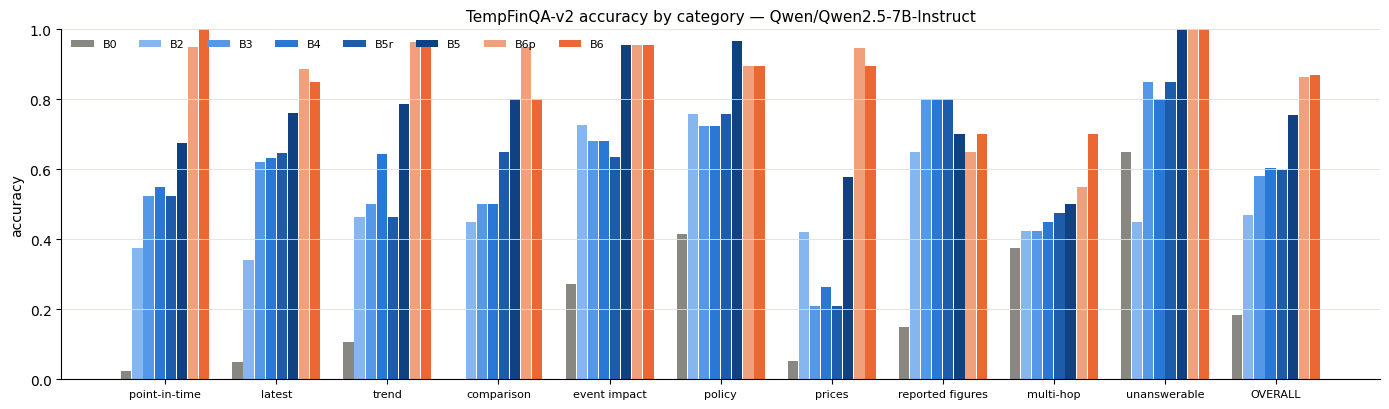

51 questions where B6 is right and B5 is wrong, e.g.:
              category                                                                                                      question     truth        B5        B6
qid                                                                                                                                                              
v2q000  point-in-time                          Was news coverage of Tesla in March 2023 mostly positive, mostly negative, or mixed?     mixed  negative     mixed
v2q005  point-in-time                           Was news coverage of Apple in June 2022 mostly positive, mostly negative, or mixed?     mixed  positive     mixed
v2q006  point-in-time                   Was news coverage of Microsoft in February 2023 mostly positive, mostly negative, or mixed?     mixed  negative     mixed
v2q009  point-in-time                          Was news coverage of Nvidia in June 2022 mostly positive, mostly negative, or mixed?    

In [13]:
# Figures (palette: grey = no retrieval; blues = retrieval versions, darker = later; orange = B6 versions)
VCOL = {"B0": "#898781", "B2": "#86b6ef", "B3": "#5598e7", "B4": "#2a78d6", "B5r": "#1c5cab", "B5": "#104281", "B6p": "#f0a07a", "B6": "#eb6834"}
fig, ax = plt.subplots(figsize=(14, 4.2)); xs = cats + ["OVERALL"]; w = 0.8 / len(DONE_V)
for k, v in enumerate(DONE_V):
    ax.bar(np.arange(len(xs)) + k * w, [by_cat.loc[v, c] for c in xs], w * 0.92, label=v, color=VCOL.get(v, "#999"))
ax.set_xticks(np.arange(len(xs)) + w * (len(DONE_V) - 1) / 2); ax.set_xticklabels(xs, fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.legend(ncol=len(DONE_V), fontsize=8, frameon=False, loc="upper left")
ax.grid(axis="y", color="#e1e0d9", lw=.6); [ax.spines[s].set_visible(False) for s in ("top", "right")]
ax.set_title(f"TempFinQA-v2 accuracy by category — {LLM_MODEL}", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "figures" / "accuracy_by_category.png", dpi=160); plt.show()

wide = res.pivot(index="qid", columns="version", values="pred"); okw = res.pivot(index="qid", columns="version", values="correct")
if {"B6", "B5"} <= set(DONE_V):
    diff = questions.set_index("qid").loc[okw.index[(okw["B6"] == True) & (okw["B5"] == False)], ["category", "question", "truth"]].join(wide[["B5", "B6"]])
    print(f"{len(diff)} questions where B6 is right and B5 is wrong, e.g.:\n", diff.head(8).to_string())

## Step 10 — Sensitivity of the decay settings (qwen7b run only)

Recency decay has two knobs: the **half-life** (how fast old documents lose weight) and **λ** (how much the decay counts relative to relevance). We re-run B4 on the "latest" questions with half-lives 7–120 days and λ 0.25–0.75, and B5's event-anchored decay on event and policy questions with half-lives 1–20 days.

In [14]:
sens_rows = []
if SENSITIVITY and hours() < MAX_HOURS - 1.0 and "B4" in GEN:
    latest_q = questions[questions.category == "latest"]
    event_q = questions[questions.template.isin(["T7 earnings impact", "T11 policy impact"])]
    grid = [("B4", hl, lam, None) for hl, lam in [(7, .5), (14, .5), (60, .5), (120, .5), (30, .25), (30, .75)]]
    grid += [("B5", None, None, he) for he in (1, 2, 10, 20)] if "B5" in GEN else []
    base_ok = res.set_index(["qid", "version"]).correct
    for v, hl, lam, he in grid:
        if hours() > MAX_HOURS - 0.6: print("⏱ time limit: stopping the sensitivity study"); break
        qs = latest_q if v == "B4" else event_q
        pairs, keep = [], []
        for q in qs.itertuples():
            ev_ = retrieve(q, "B4" if v == "B4" else "B5r", PLANS[q.qid], hl=hl, lam=lam, hl_event=he)
            pairs.append(answer_prompt(q, v, evid=ev_)); keep.append(q)
        outs = llm.chat(pairs, max_new_tokens=MAX_NEW_TOKENS, batch_size=LLM_BATCH, name=f"{v} hl={hl or he} λ={lam}")
        okv = []
        for q, o in zip(keep, outs):
            pr = normalize(q, parse_json(o).get("answer", ""))
            if v == "B5" and GUARD[q.qid]: pr = "insufficient data"
            okv.append(is_correct(q, pr))
        sens_rows.append({"version": v, "half_life": hl or he, "lambda": lam if lam is not None else LAMBDA, "questions": qs.category.iloc[0] if v == "B4" else "event + policy",
                          "n": len(keep), "accuracy": np.mean(okv)})
    base = [{"version": "B4", "half_life": HALF_LIFE_DAYS, "lambda": LAMBDA, "questions": "latest", "n": len(latest_q),
             "accuracy": base_ok.loc[[(q, "B4") for q in latest_q.qid]].mean()}]
    if "B5" in GEN:
        base.append({"version": "B5", "half_life": HALF_LIFE_EVENT, "lambda": LAMBDA, "questions": "event + policy", "n": len(event_q),
                     "accuracy": base_ok.loc[[(q, "B5") for q in event_q.qid]].mean()})
    sens = pd.DataFrame(base + sens_rows).sort_values(["version", "lambda", "half_life"])
    print(sens.round(3).to_string(index=False)); sens.to_csv(OUT / "sensitivity.csv", index=False)
    SUMMARY["sensitivity"] = sens.round(3).to_dict("records")
else:
    print("Sensitivity study skipped.")

  OOM → batch size 6
  B4 hl=7 λ=0.5: 60/79 |   234s
  B4 hl=7 λ=0.5: 79/79 |   303s
  OOM → batch size 6
  B4 hl=14 λ=0.5: 60/79 |   229s
  B4 hl=14 λ=0.5: 79/79 |   298s
  OOM → batch size 6
  B4 hl=60 λ=0.5: 60/79 |   233s
  B4 hl=60 λ=0.5: 79/79 |   302s
  OOM → batch size 6
  B4 hl=120 λ=0.5: 60/79 |   221s
  B4 hl=120 λ=0.5: 79/79 |   294s
  OOM → batch size 6
  B4 hl=30 λ=0.25: 60/79 |   228s
  B4 hl=30 λ=0.25: 79/79 |   299s
  OOM → batch size 6
  B4 hl=30 λ=0.75: 60/79 |   236s
  B4 hl=30 λ=0.75: 79/79 |   307s
  B5 hl=1 λ=None: 39/39 |   164s
  B5 hl=2 λ=None: 39/39 |   168s
  B5 hl=10 λ=None: 39/39 |   170s
  B5 hl=20 λ=None: 39/39 |   167s
version  half_life  lambda      questions  n  accuracy
     B4         30    0.25         latest 79     0.633
     B4          7    0.50         latest 79     0.620
     B4         14    0.50         latest 79     0.595
     B4         30    0.50         latest 79     0.633
     B4         60    0.50         latest 79     0.595
     B4   

## Step 11 — Faithfulness of the explanations (NLI)

An NLI model checks whether each one-sentence explanation is **entailed** by what the system was shown: the cited documents and, for B5/B6, the tool outputs. This measures whether the explanations are grounded, separately from whether the answers are right.

In [15]:
try:
    if N_GPU: torch.cuda.empty_cache()
    nli = CrossEncoder(NLI_MODEL, device=DEV0, max_length=512)
    if N_GPU:
        try: nli.model.half()
        except Exception: pass
    id2 = {int(k): v.lower() for k, v in nli.model.config.id2label.items()}
    ENT = next(i for i, v in id2.items() if v.startswith("entail"))
    def premise(q, v, cited):
        idx = EVID[(q.qid, v)][0]
        ids = [DOC_IX[c] for c in cited if c in DOC_IX and DOC_IX[c] in idx] or idx[:3]
        tool = tools_text(q, v)[:1200] + "\n" if v in ("B5", "B6p", "B6") else ""
        return tool + " ".join(TEXT[i][:400] for i in ids)
    pairs, keys = [], []
    for v in [v for v in DONE_V if v != "B0"]:
        for q, raw in zip(questions.itertuples(), GEN[v]):
            p = parse_json(raw); ex_ = str(p.get("explanation", "")).strip()
            if len(ex_) < 15 or INSUFF.search(ex_): continue
            pairs.append((premise(q, v, [c for c in (p.get("doc_ids") or []) if isinstance(c, str)]), ex_)); keys.append((q.qid, v))
    sc = np.asarray(nli.predict(pairs, batch_size=16, apply_softmax=True, show_progress_bar=False), dtype=np.float32)
    faith = pd.DataFrame(keys, columns=["qid", "version"]); faith["entail"] = sc[:, ENT]; faith["supported"] = sc.argmax(1) == ENT
    fs = faith.groupby("version").agg(n=("supported", "size"), supported=("supported", "mean"), mean_entail=("entail", "mean")).reindex([v for v in DONE_V if v != "B0"]).round(3)
    print("Explanations entailed by the evidence shown (NLI):\n", fs.to_string()); fs.to_csv(OUT / "faithfulness.csv")
    SUMMARY["faithfulness"] = fs.to_dict("index")
except Exception:
    traceback.print_exc(); print("⚠️ NLI faithfulness check skipped.")

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Explanations entailed by the evidence shown (NLI):
            n  supported  mean_entail
version                             
B2       306      0.127        0.131
B3       288      0.062        0.067
B4       292      0.038        0.047
B5r      289      0.069        0.070
B5       301      0.063        0.068
B6p      294      0.003        0.019
B6       305      0.033        0.041


## Step 12 — Structured reports for headline questions (B6)

The final product: for each headline question, a **structured JSON report**. The numbers (sentiment timeline per source, events with CAR, price moves) come straight from the tools. The LLM writes the narrative (summary, turning points, caveats), citing documents, and every narrative sentence is checked by NLI against what it cites.

  router: 1/1 |     5s
  router: 1/1 |     5s
  router: 1/1 |     7s
  router: 1/1 |     5s
  reports: 4/4 |   118s

### How has Tesla's sentiment changed over the last 2 years?
{
 "summary": "Tesla's sentiment has fluctuated significantly over the last two years, showing periods of both positivity and negativity. Notably, sentiment improved in 2023, particularly in June and July, while it deteriorated notably in December 2022 and January 2023.",
 "turning_points": [
  {
   "date": "2022-06",
   "what_changed": "Sentiment turned positive, likely due to positive earnings reports and market optimism.",
   "doc_ids": [
    "fil_TSLA_000156459022033053_0"
   ]
  },
  {
   "date": "2023-01",
   "what_changed": "Sentiment took a sharp downturn, possibly due to lower-than-expected deliveries and market concerns.",
   "doc_ids": [
    "news_0014368",
    "news_0014381",
    "news_0014312"
   ]
  },
  {
   "date": "2023-06",
   "what_changed": "Sentiment reached a high point, likely influenced 

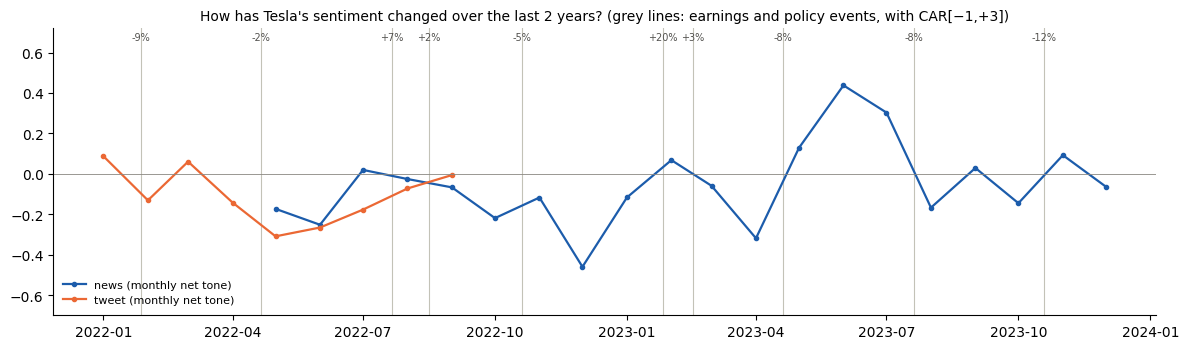

In [16]:
SHOW = [("How has Tesla's sentiment changed over the last 2 years?", "TSLA", END),
        ("What drove Nvidia's stock in October 2022, and how did news sentiment react?", "NVDA", END),
        ("How did Apple's stock react to its earnings report in early November 2023?", "AAPL", END),
        ("How did US regulatory actions affect Microsoft in 2022 and 2023?", "MSFT", END)]
reports = []
if SHOWCASE and hours() < MAX_HOURS - 0.3:
    REPORT_FMT = ('{"summary": "<3-5 sentences>", "turning_points": [{"date": "YYYY-MM", "what_changed": "<one sentence>", "doc_ids": ["..."]}], '
                  '"event_insights": [{"date": "YYYY-MM-DD", "insight": "<one sentence: event and market reaction; say coincided with, not caused>", "doc_ids": ["..."]}], '
                  '"caveats": ["<coverage limits or uncertainty>"]}')
    pairs = []
    for qtext, t, a in SHOW:
        p = make_plan(llm.chat([(ROUTER_SYSTEM, router_user(a, qtext))], max_new_tokens=160, name="router")[0], a)
        qq = SimpleNamespace(qid=f"show_{t}", ticker=t, query=qtext, question=qtext, as_of=a, sources=["news", "social", "filing"], answer_type="free")
        PLANS[qq.qid] = p
        idx, note = retrieve(qq, "B5r", p)
        idx = idx + [i for i in graph_docs(qq, p, k=4) if i not in idx]
        EVID[(qq.qid, "B6")] = (idx, note)
        tl = [timeline_block(SimpleNamespace(**{**vars(qq), "sources": [s]}), p) for s in ("news", "social") if (t, s) in COV]
        tools = "\n\n".join(tl + [events_block(qq, p), price_block(qq, p), graph_block(qq, p)])
        sys_ = (f"You are a careful financial analyst. Today is {a}; you know nothing after this date. Use ONLY the information below. "
                "Reply with one JSON object only.")
        pairs.append((sys_, f"{tools}\n\n{evidence_block(idx, note, qtext)}\n\nQuestion: {qtext}\nWrite a structured report. JSON: {REPORT_FMT}"))
        reports.append({"question": qtext, "ticker": t, "as_of": a, "router": {k: str(v) for k, v in p.items() if k != "raw"}, "_tools": tools, "_idx": idx})
    outs = llm.chat(pairs, max_new_tokens=700, batch_size=2, name="reports")
    for r, o in zip(reports, outs):
        j = parse_json(o); idx = r.pop("_idx"); tools = r.pop("_tools")
        t, a = r["ticker"], r["as_of"]
        tl = {}
        for s in ("news", "social"):
            if (t, s) in COV:
                g = period_table(t, s, "M"); g = g[g.ok & (g.end <= ts(a)) & (g.start >= PLANS[f"show_{t}"]["start"].replace(day=1))]
                tl[s] = [{"month": p_.strftime("%Y-%m"), "tone": round(float(x), 3), "n": int(n)} for p_, x, n in zip(g.per, g.tone, g.n)]
        evs = [ln[2:] for ln in events_block(SimpleNamespace(qid="", ticker=t, as_of=a), PLANS[f"show_{t}"]).split("\n")[1:]]
        given = set(DOC_ID[i] for i in idx)
        claims = [("summary", s) for s in re.split(r"(?<=[.!?])\s+", str(j.get("summary", ""))) if len(s) > 20]
        for k in ("turning_points", "event_insights"):
            for it in (j.get(k) or []):
                if isinstance(it, dict):
                    claims.append((k, str(it.get("what_changed") or it.get("insight") or ""), [d for d in (it.get("doc_ids") or []) if d in given]))
        checks = []
        for c in claims:
            kind, text = c[0], c[1]; cited = c[2] if len(c) > 2 else []
            prem = (tools[:1500] + " " + " ".join(TEXT[DOC_IX[d]][:400] for d in cited))[:3000]
            try:
                pr = np.asarray(nli.predict([(prem, text)], apply_softmax=True, show_progress_bar=False))[0]
                checks.append({"part": kind, "claim": text, "cited": cited, "entailment": round(float(pr[ENT]), 3), "supported": bool(pr.argmax() == ENT)})
            except Exception:
                checks.append({"part": kind, "claim": text, "cited": cited, "entailment": None, "supported": None})
        r.update({"timeline": tl, "events": evs, "narrative": {k: j.get(k) for k in ("summary", "turning_points", "event_insights", "caveats")},
                  "citation_validity": float(np.mean([d in given for k in ("turning_points", "event_insights") for it in (j.get(k) or []) if isinstance(it, dict) for d in (it.get("doc_ids") or [])] or [np.nan])),
                  "faithfulness": {"claims": len(checks), "supported": float(np.mean([c["supported"] for c in checks if c["supported"] is not None] or [np.nan])), "checks": checks}})
        print(f"\n### {r['question']}\n{json.dumps(r['narrative'], indent=1)[:1800]}\n→ claims supported by NLI: {r['faithfulness']['supported']:.0%} of {len(checks)}")
    (OUT / "showcase_reports.json").write_text(json.dumps(reports, indent=1, default=str))
    SUMMARY["showcase"] = [{"q": r["question"], "claims": r["faithfulness"]["claims"], "supported": round(r["faithfulness"]["supported"], 3) if r["faithfulness"]["supported"] == r["faithfulness"]["supported"] else None} for r in reports]

    # figure: Tesla over two years — news and tweets, with earnings and policy events
    t = "TSLA"; s2 = END_TS - pd.DateOffset(years=2) + D(days=1)
    fig, ax = plt.subplots(figsize=(12, 3.6))
    for s, col in (("news", "#1c5cab"), ("social", "#eb6834")):
        if (t, s) in COV:
            g = period_table(t, s, "M"); g = g[g.ok & (g.start >= s2)]
            ax.plot(g.per.dt.to_timestamp(), g.tone, marker="o", ms=3, lw=1.6, color=col, label=f"{SRC_NAME[s]} (monthly net tone)")
    for r in EVT[(EVT.ticker == t) & (EVT.label.isin(["earnings", "policy action"])) & (EVT.day0 >= s2)].itertuples():
        ax.axvline(r.day0, color="#c3c2b7", lw=.8, zorder=0)
        if pd.notna(r.car_m1_p3): ax.text(r.day0, 0.62, f"{r.car_m1_p3:+.0%}", fontsize=7, color="#52514e", ha="center")
    lo_, hi_ = ax.get_ylim(); top = max(0.72, hi_ + 0.12)
    for txt in ax.texts: txt.set_y(top - 0.06)
    ax.axhline(0, color="#898781", lw=.6); ax.set_ylim(min(-0.7, lo_ - 0.05), top); ax.legend(fontsize=8, frameon=False, loc="lower left")
    [ax.spines[sp].set_visible(False) for sp in ("top", "right")]
    ax.set_title("How has Tesla's sentiment changed over the last 2 years? (grey lines: earnings and policy events, with CAR[−1,+3])", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "showcase_tesla_2y.png", dpi=160); plt.show()
else:
    print("Showcase skipped.")

In [17]:
SUMMARY["total_minutes"] = round((time.time() - T0) / 60, 1)
(OUT / "summary.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):36s} {f.stat().st_size/1e6:7.2f} MB")
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

answers_scored.parquet                  0.15 MB
faithfulness.csv                        0.00 MB
figures/accuracy_by_category.png        0.05 MB
figures/showcase_tesla_2y.png           0.09 MB
gen_B0.parquet                          0.03 MB
gen_B2.parquet                          0.03 MB
gen_B3.parquet                          0.03 MB
gen_B4.parquet                          0.03 MB
gen_B5.parquet                          0.04 MB
gen_B5r.parquet                         0.03 MB
gen_B6.parquet                          0.07 MB
gen_B6p.parquet                         0.07 MB
mcnemar.csv                             0.00 MB
overall_ci.csv                          0.00 MB
plans.parquet                           0.01 MB
questions_v2.parquet                    0.04 MB
results_by_category.csv                 0.00 MB
results_by_template.csv                 0.00 MB
retrieval_per_question.csv              0.07 MB
retrieval_summary.csv                   0.00 MB
router_eval.csv                         